# 01 — EDA | Bank Marketing (propensão a depósito a prazo)

**Objetivo do projeto:** estimar a probabilidade de um cliente contratar o depósito a prazo (`y = yes`) após o contato de telemarketing.

**Convenção:** o evento de interesse é a **conversão** (`y = 1`, o "bom"). Onde em crédito usaríamos *taxa de maus*, aqui usamos **taxa de conversão** — a mecânica é a mesma (volume, % público, taxa do evento, lift, WoE e IV).

**Roteiro**
1. Setup e leitura
2. Metadados (preenchimento, nulls, tipos, valores)
3. Target
4. Estudo de público — variáveis categóricas
5. Estudo de público — variáveis numéricas e faixas
6. `duration` (vazamento)
7. Correlações (Pearson, Spearman, com o target, Cramér's V)
8. Ranking de IV
9. Visão temporal (macro × conversão)
10. Cruzamentos de perfil
11. Conclusões

## 1. Setup e leitura

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titleweight'] = 'bold'

In [2]:
from google.colab import drive
drive.mount('/content/drive')
file_path_base = r'/content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Base/bank-additional-full.csv'


df_base = pd.read_csv(file_path_base, sep=';')
print(f'Linhas: {df_base.shape[0]:,} | Colunas: {df_base.shape[1]}')
df_base.head()

Mounted at /content/drive
Linhas: 41,188 | Colunas: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no


In [3]:
# Cópia de trabalho + target numérico (1 = contratou)
df = df_base.copy()
df['target'] = (df['y'] == 'yes').astype(int)

TARGET = 'target'
TAXA_GERAL = df[TARGET].mean()

COLS_CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
COLS_NUM_CLIENTE = ['age', 'campaign', 'pdays', 'previous']
COLS_MACRO = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
COL_VAZAMENTO = ['duration']
COLS_NUM = COLS_NUM_CLIENTE + COLS_MACRO

print(f'Taxa geral de conversão: {TAXA_GERAL:.2%}')

Taxa geral de conversão: 11.27%


## 2. Metadados

Tabela única com tipo, preenchimento, nulos, valores `unknown` (o "nulo disfarçado" desta base), cardinalidade e exemplos de valores.

In [4]:
def tabela_metadados(data):
    linhas = []
    for col in data.columns:
        s = data[col]
        numerica = pd.api.types.is_numeric_dtype(s)
        n_unknown = 0 if numerica else (s == 'unknown').sum()
        linhas.append({
            'coluna': col,
            'tipo': str(s.dtype),
            'qtd_preenchida': s.notna().sum(),
            'qtd_null': s.isna().sum(),
            'pct_null': s.isna().mean(),
            'qtd_unknown': n_unknown,
            'pct_unknown': n_unknown / len(s),
            'qtd_distintos': s.nunique(),
            'min': s.min() if numerica else None,
            'max': s.max() if numerica else None,
            'exemplos': list(s.dropna().unique()[:5]),
        })
    return pd.DataFrame(linhas)

meta = tabela_metadados(df_base)
meta.style.format({'pct_null': '{:.2%}', 'pct_unknown': '{:.2%}'}) \
    .background_gradient(subset=['pct_unknown'], cmap='Reds')

,coluna,tipo,qtd_preenchida,qtd_null,pct_null,qtd_unknown,pct_unknown,qtd_distintos,min,max,exemplos
0,age,int64,41188,0,0.00%,0,0.00%,78,17.000000,98.000000,"[np.int64(56), np.int64(57), np.int64(37), np.int64(40), np.int64(45)]"
1,job,object,41188,0,0.00%,330,0.80%,12,nan,nan,"['housemaid', 'services', 'admin.', 'blue-collar', 'technician']"
2,marital,object,41188,0,0.00%,80,0.19%,4,nan,nan,"['married', 'single', 'divorced', 'unknown']"
3,education,object,41188,0,0.00%,1731,4.20%,8,nan,nan,"['basic.4y', 'high.school', 'basic.6y', 'basic.9y', 'professional.course']"
4,default,object,41188,0,0.00%,8597,20.87%,3,nan,nan,"['no', 'unknown', 'yes']"
5,housing,object,41188,0,0.00%,990,2.40%,3,nan,nan,"['no', 'yes', 'unknown']"
6,loan,object,41188,0,0.00%,990,2.40%,3,nan,nan,"['no', 'yes', 'unknown']"
7,contact,object,41188,0,0.00%,0,0.00%,2,nan,nan,"['telephone', 'cellular']"
8,month,object,41188,0,0.00%,0,0.00%,10,nan,nan,"['may', 'jun', 'jul', 'aug', 'oct']"
9,day_of_week,object,41188,0,0.00%,0,0.00%,5,nan,nan,"['mon', 'tue', 'wed', 'thu', 'fri']"


In [5]:
# Duplicatas
qtd_dup = df_base.duplicated().sum()
print(f'Linhas duplicadas: {qtd_dup} ({qtd_dup / len(df_base):.3%})')
df_base[df_base.duplicated(keep=False)].sort_values(list(df_base.columns)).head(10)

Linhas duplicadas: 12 (0.029%)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8000,93.0750,-47.1000,1.4230,"5,099.1000",no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8000,93.0750,-47.1000,1.4230,"5,099.1000",no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9620,"5,228.1000",no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9620,"5,228.1000",no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9680,"5,228.1000",no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9680,"5,228.1000",no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8000,92.8930,-46.2000,1.3130,"5,099.1000",no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8000,92.8930,-46.2000,1.3130,"5,099.1000",no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9660,"5,228.1000",no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4000,93.9180,-42.7000,4.9660,"5,228.1000",no


In [6]:
# Estatísticas descritivas — numéricas
df_base.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
age,"41,188.0000",40.0241,10.4212,17.0000,23.0000,26.0000,32.0000,38.0000,47.0000,58.0000,71.0000,98.0000
duration,"41,188.0000",258.2850,259.2792,0.0000,11.0000,36.0000,102.0000,180.0000,319.0000,752.6500,"1,271.1300","4,918.0000"
campaign,"41,188.0000",2.5676,2.7700,1.0000,1.0000,1.0000,1.0000,2.0000,3.0000,7.0000,14.0000,56.0000
pdays,"41,188.0000",962.4755,186.9109,0.0000,3.0000,999.0000,999.0000,999.0000,999.0000,999.0000,999.0000,999.0000
previous,"41,188.0000",0.1730,0.4949,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,7.0000
emp.var.rate,"41,188.0000",0.0819,1.5710,-3.4000,-3.4000,-2.9000,-1.8000,1.1000,1.4000,1.4000,1.4000,1.4000
cons.price.idx,"41,188.0000",93.5757,0.5788,92.2010,92.2010,92.7130,93.0750,93.7490,93.9940,94.4650,94.4650,94.7670
cons.conf.idx,"41,188.0000",-40.5026,4.6282,-50.8000,-49.5000,-47.1000,-42.7000,-41.8000,-36.4000,-33.6000,-26.9000,-26.9000
euribor3m,"41,188.0000",3.6213,1.7344,0.6340,0.6585,0.7970,1.3440,4.8570,4.9610,4.9660,4.9680,5.0450
nr.employed,"41,188.0000","5,167.0359",72.2515,"4,963.6000","4,963.6000","5,017.5000","5,099.1000","5,191.0000","5,228.1000","5,228.1000","5,228.1000","5,228.1000"


In [7]:
# Estatísticas descritivas — categóricas
df_base.describe(exclude='number').T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [8]:
# Valores sentinela / pontos de atenção
print(f"pdays == 999 (nunca contatado antes): {(df['pdays'] == 999).mean():.2%}")
print(f"previous == 0: {(df['previous'] == 0).mean():.2%}")
print(f"poutcome == 'nonexistent': {(df['poutcome'] == 'nonexistent').mean():.2%}")
print(f"default == 'yes': {(df['default'] == 'yes').sum()} linhas")
print(f"education == 'illiterate': {(df['education'] == 'illiterate').sum()} linhas")
print('\nMeses presentes:', sorted(df['month'].unique()))
print('Dias presentes:', sorted(df['day_of_week'].unique()))

pdays == 999 (nunca contatado antes): 96.32%
previous == 0: 86.34%
poutcome == 'nonexistent': 86.34%
default == 'yes': 3 linhas
education == 'illiterate': 18 linhas

Meses presentes: ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Dias presentes: ['fri', 'mon', 'thu', 'tue', 'wed']


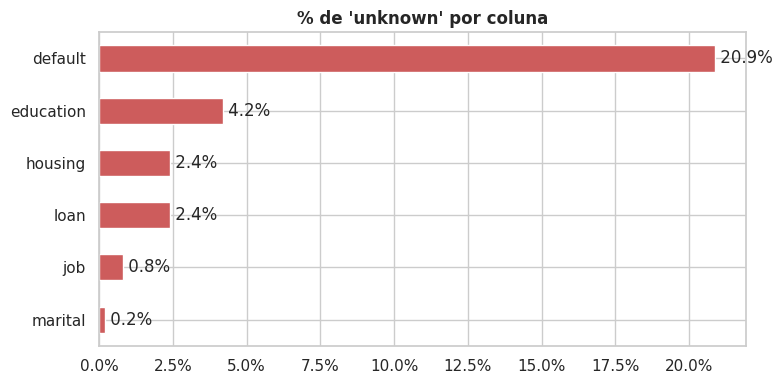

In [9]:
# Gráfico: % de 'unknown' por coluna
unk = meta.loc[meta['pct_unknown'] > 0, ['coluna', 'pct_unknown']].sort_values('pct_unknown')
ax = unk.plot.barh(x='coluna', y='pct_unknown', legend=False, color='indianred', figsize=(8, 4))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
for i, v in enumerate(unk['pct_unknown']):
    ax.text(v, i, f' {v:.1%}', va='center')
ax.set_title("% de 'unknown' por coluna"); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 3. Target

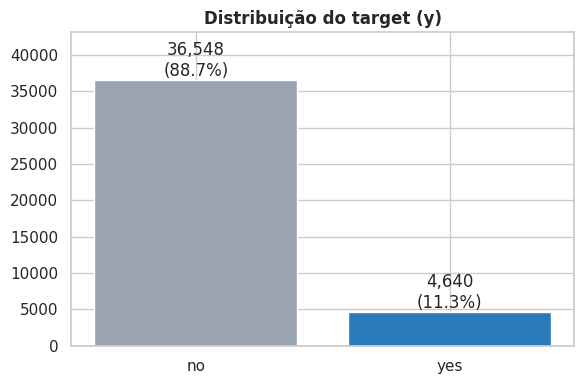

Razão no/yes: 7.9 : 1  → base desbalanceada


In [10]:
vc = df['y'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(vc.index, vc.values, color=['#9aa5b1', '#2a7ab9'])
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / vc.sum():.1%})', ha='center', va='bottom')
ax.set_title('Distribuição do target (y)'); ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout(); plt.show()
print(f'Razão no/yes: {vc["no"] / vc["yes"]:.1f} : 1  → base desbalanceada')

## 4. Estudo de público — variáveis categóricas

Função padrão: para cada categoria → **Qtd, % público, Conversões, Taxa de conversão, Lift, WoE, IV**.

- `WoE = ln(% bons / % maus)` (bom = converteu). WoE > 0 → categoria converte acima da média.
- `IV` = soma de `(% bons − % maus) × WoE`. Regra de bolso: < 0,02 inútil · 0,02–0,1 fraca · 0,1–0,3 média · 0,3–0,5 forte · > 0,5 suspeita (checar vazamento).

In [11]:
def tabela_categoria(data, col, target=TARGET, ordenar_por=None, suav=0.5):
    g = data.groupby(col, observed=True)[target].agg(qtd='count', conversoes='sum')
    g['nao_conversoes'] = g['qtd'] - g['conversoes']
    g['pct_publico'] = g['qtd'] / g['qtd'].sum()
    g['taxa_conversao'] = g['conversoes'] / g['qtd']
    g['lift'] = g['taxa_conversao'] / data[target].mean()
    pct_bons = (g['conversoes'] + suav) / (g['conversoes'].sum() + suav)
    pct_maus = (g['nao_conversoes'] + suav) / (g['nao_conversoes'].sum() + suav)
    g['woe'] = np.log(pct_bons / pct_maus)
    g['iv'] = (pct_bons - pct_maus) * g['woe']
    if ordenar_por:
        g = g.sort_values(ordenar_por, ascending=False)
    return g[['qtd', 'pct_publico', 'conversoes', 'taxa_conversao', 'lift', 'woe', 'iv']]


def estilo(tab):
    return (tab.style
            .format({'qtd': '{:,.0f}', 'conversoes': '{:,.0f}', 'pct_publico': '{:.1%}',
                     'taxa_conversao': '{:.1%}', 'lift': '{:.2f}', 'woe': '{:.3f}', 'iv': '{:.4f}'})
            .background_gradient(subset=['taxa_conversao'], cmap='RdYlGn')
            .bar(subset=['pct_publico'], color='#9ecae1'))


def plot_volume_taxa(tab, titulo, rot=0, figsize=(12, 4.5)):
    fig, ax1 = plt.subplots(figsize=figsize)
    x = tab.index.astype(str)
    ax1.bar(x, tab['qtd'], color='#c6dbef', edgecolor='#6baed6')
    ax1.set_ylabel('Qtd de clientes')
    ax2 = ax1.twinx()
    ax2.plot(x, tab['taxa_conversao'], color='#d94801', marker='o', lw=2)
    ax2.axhline(TAXA_GERAL, ls='--', color='grey', lw=1)
    ax2.text(-0.45, TAXA_GERAL, f'média {TAXA_GERAL:.1%}', va='bottom', ha='left', color='grey', fontsize=9)
    for xi, v in zip(x, tab['taxa_conversao']):
        ax2.annotate(f'{v:.1%}', (xi, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9, color='#d94801')
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax2.set_ylim(0, tab['taxa_conversao'].max() * 1.25)
    ax2.set_ylabel('Taxa de conversão'); ax2.grid(False)
    ax1.set_title(f'{titulo} — volume × taxa de conversão  (IV = {tab["iv"].sum():.3f})')
    plt.setp(ax1.get_xticklabels(), rotation=rot, ha='right' if rot else 'center')
    plt.tight_layout(); plt.show()


ORDEM_MES = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
ORDEM_DIA = ['mon', 'tue', 'wed', 'thu', 'fri']
ORDEM_EDU = ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y', 'high.school',
             'professional.course', 'university.degree', 'unknown']
ORDENS = {'month': ORDEM_MES, 'day_of_week': ORDEM_DIA, 'education': ORDEM_EDU}


def analisar_categoria(col, rot=0):
    tab = tabela_categoria(df, col)
    tab = tab.reindex(ORDENS[col]) if col in ORDENS else tab.sort_values('qtd', ascending=False)
    display(estilo(tab))
    plot_volume_taxa(tab, col, rot=rot)
    return tab

### 4.1 `job`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
job,,,,,,,
admin.,"10,422",25.3%,"1,352",13.0%,1.15,0.161,0.0070
blue-collar,"9,254",22.5%,638,6.9%,0.61,-0.538,0.0529
technician,"6,743",16.4%,730,10.8%,0.96,-0.044,0.0003
services,"3,969",9.6%,323,8.1%,0.72,-0.359,0.0108
management,"2,924",7.1%,328,11.2%,1.00,-0.004,0.0000
retired,"1,720",4.2%,434,25.2%,2.24,0.978,0.0572
entrepreneur,"1,456",3.5%,124,8.5%,0.76,-0.307,0.0030
self-employed,"1,421",3.5%,149,10.5%,0.93,-0.078,0.0002
housemaid,"1,060",2.6%,106,10.0%,0.89,-0.129,0.0004


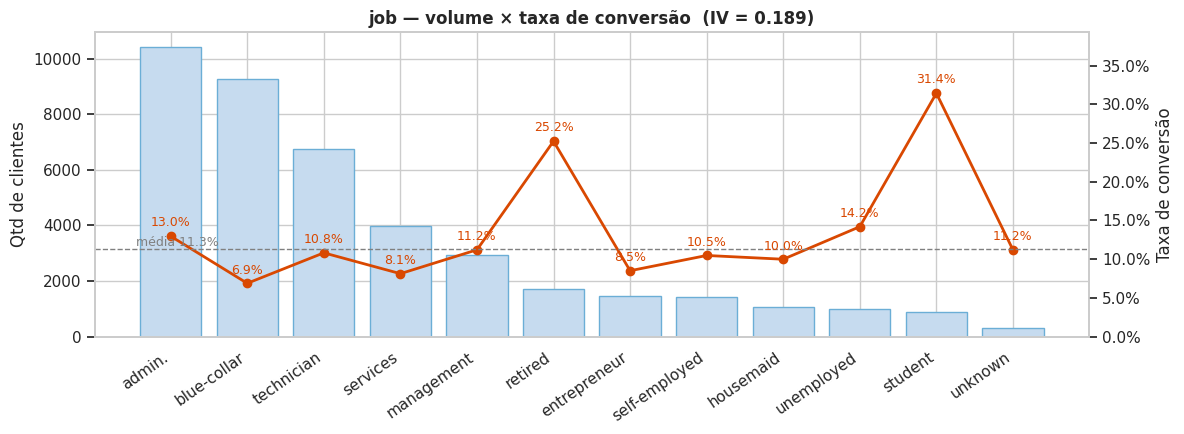

In [12]:
tab_job = analisar_categoria('job', rot=35)

### 4.2 `marital`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
marital,,,,,,,
married,"24,928",60.5%,"2,532",10.2%,0.90,-0.116,0.0078
single,"11,568",28.1%,"1,620",14.0%,1.24,0.249,0.0192
divorced,"4,612",11.2%,476,10.3%,0.92,-0.097,0.0010
unknown,80,0.2%,12,15.0%,1.33,0.363,0.0003


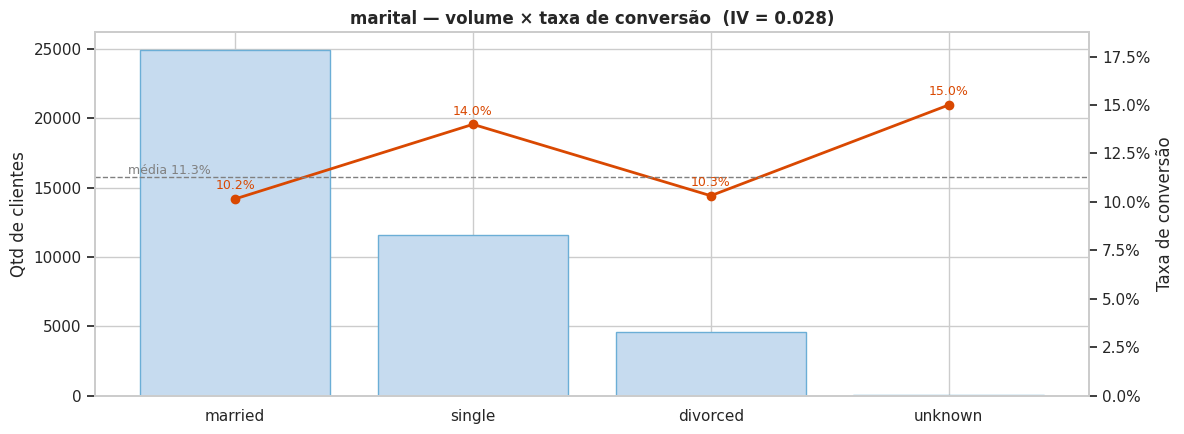

In [13]:
tab_marital = analisar_categoria('marital', rot=0)

### 4.3 `education`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
education,,,,,,,
illiterate,18,0.0%,4,22.2%,1.97,0.894,0.0005
basic.4y,"4,176",10.1%,428,10.2%,0.91,-0.105,0.0011
basic.6y,"2,292",5.6%,188,8.2%,0.73,-0.349,0.0059
basic.9y,"6,045",14.7%,473,7.8%,0.69,-0.402,0.0203
high.school,"9,515",23.1%,"1,031",10.8%,0.96,-0.043,0.0004
professional.course,"5,243",12.7%,595,11.3%,1.01,0.009,0.0000
university.degree,"12,168",29.5%,"1,670",13.7%,1.22,0.226,0.0164
unknown,"1,731",4.2%,251,14.5%,1.29,0.291,0.0040


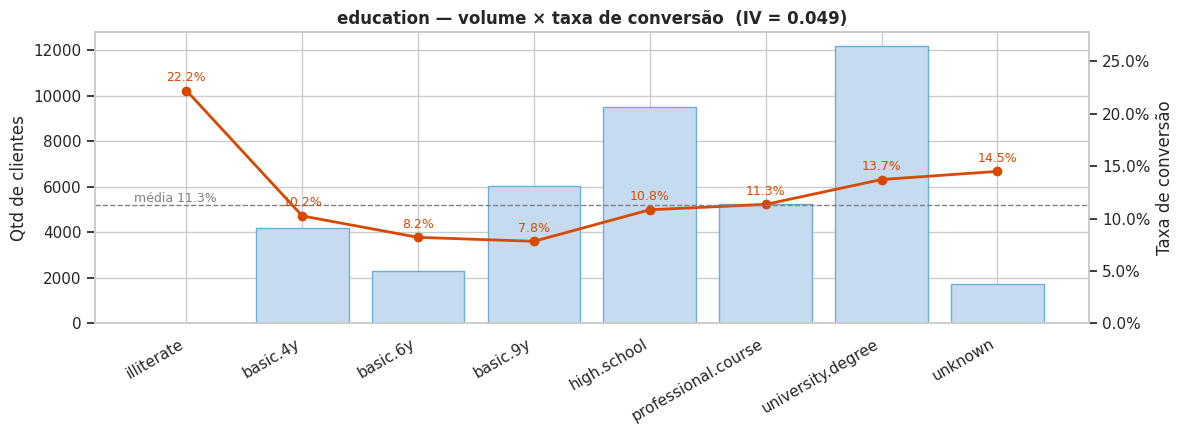

In [14]:
tab_education = analisar_categoria('education', rot=30)

### 4.4 `default`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
default,,,,,,,
no,"32,588",79.1%,"4,197",12.9%,1.14,0.152,0.0194
unknown,"8,597",20.9%,443,5.2%,0.46,-0.848,0.1081
yes,3,0.0%,0,0.0%,0.00,0.118,0.0000


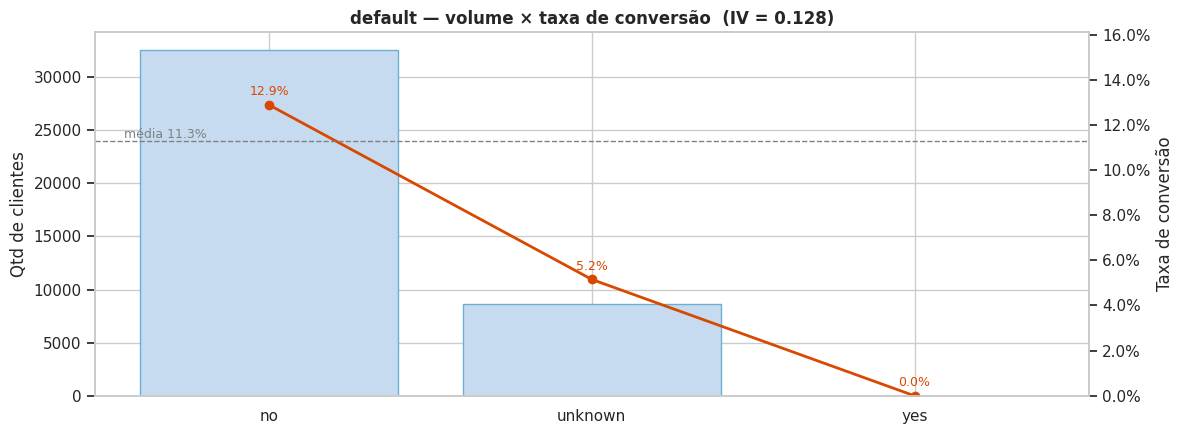

In [15]:
tab_default = analisar_categoria('default', rot=0)

### 4.5 `housing`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
housing,,,,,,,
yes,"21,576",52.4%,"2,507",11.6%,1.03,0.035,0.0007
no,"18,622",45.2%,"2,026",10.9%,0.97,-0.039,0.0007
unknown,990,2.4%,107,10.8%,0.96,-0.043,0.0000


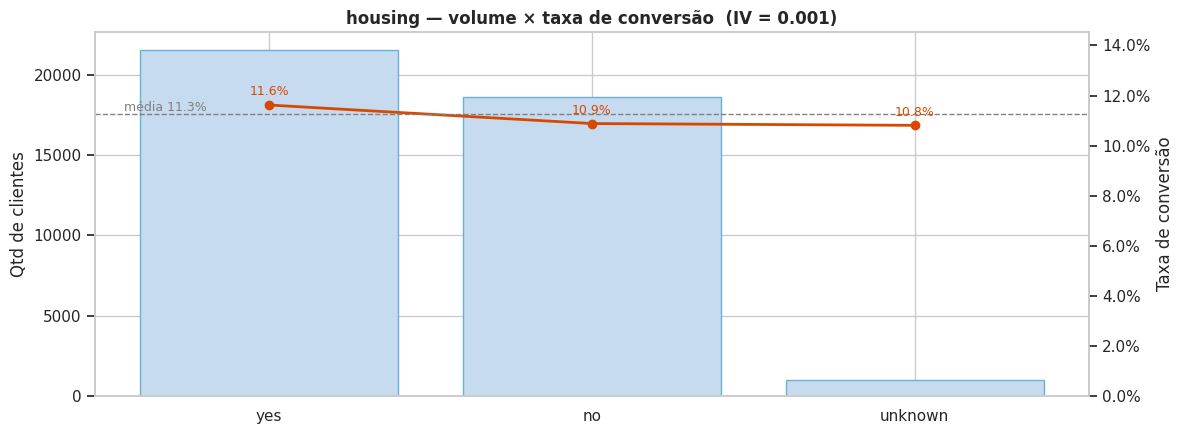

In [16]:
tab_housing = analisar_categoria('housing', rot=0)

### 4.6 `loan`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
loan,,,,,,,
no,"33,950",82.4%,"3,850",11.3%,1.01,0.007,0.0000
yes,"6,248",15.2%,683,10.9%,0.97,-0.033,0.0002
unknown,990,2.4%,107,10.8%,0.96,-0.043,0.0000


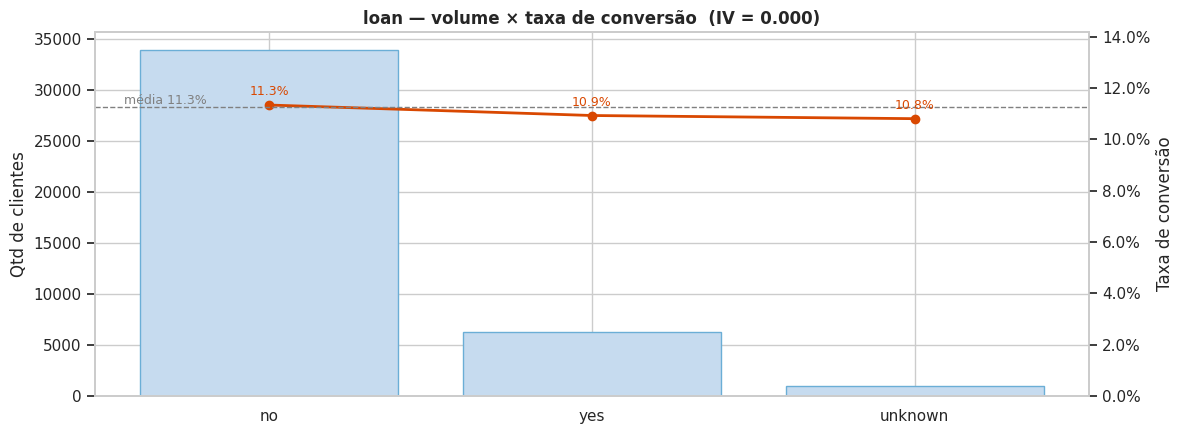

In [17]:
tab_loan = analisar_categoria('loan', rot=0)

### 4.7 `contact`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
contact,,,,,,,
cellular,"26,144",63.5%,"3,853",14.7%,1.31,0.309,0.0680
telephone,"15,044",36.5%,787,5.2%,0.46,-0.832,0.1834


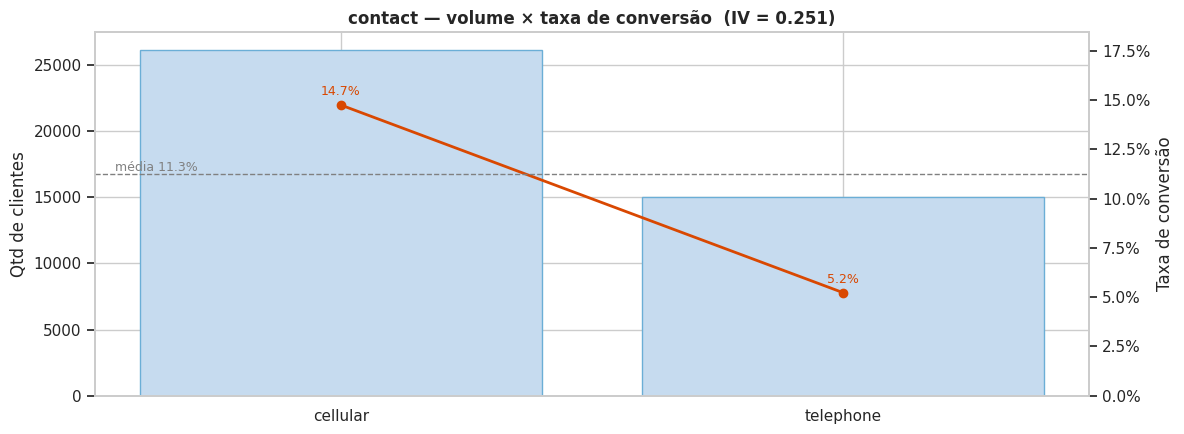

In [18]:
tab_contact = analisar_categoria('contact', rot=0)

### 4.8 `month`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
month,,,,,,,
mar,546,1.3%,276,50.5%,4.49,2.086,0.1088
apr,"2,632",6.4%,539,20.5%,1.82,0.708,0.0417
may,"13,769",33.4%,886,6.4%,0.57,-0.613,0.0989
jun,"5,318",12.9%,559,10.5%,0.93,-0.077,0.0007
jul,"7,174",17.4%,649,9.0%,0.80,-0.243,0.0094
aug,"6,178",15.0%,655,10.6%,0.94,-0.068,0.0007
sep,570,1.4%,256,44.9%,3.99,1.860,0.0868
oct,718,1.7%,315,43.9%,3.89,1.818,0.1035
nov,"4,101",10.0%,416,10.1%,0.90,-0.116,0.0013


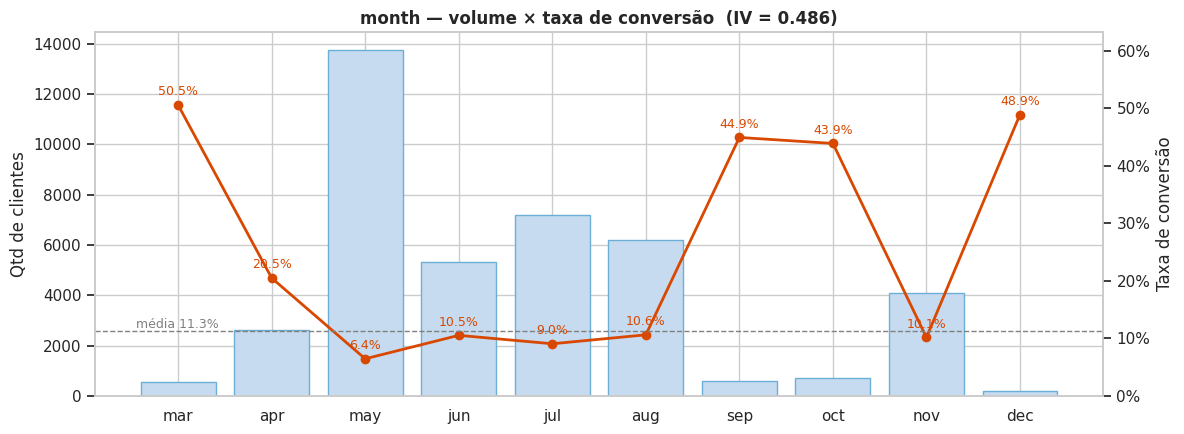

In [19]:
tab_month = analisar_categoria('month', rot=0)

### 4.9 `day_of_week`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
day_of_week,,,,,,,
mon,"8,514",20.7%,847,9.9%,0.88,-0.139,0.0038
tue,"8,090",19.6%,953,11.8%,1.05,0.051,0.0005
wed,"8,134",19.7%,949,11.7%,1.04,0.040,0.0003
thu,"8,623",20.9%,"1,045",12.1%,1.08,0.083,0.0015
fri,"7,827",19.0%,846,10.8%,0.96,-0.046,0.0004


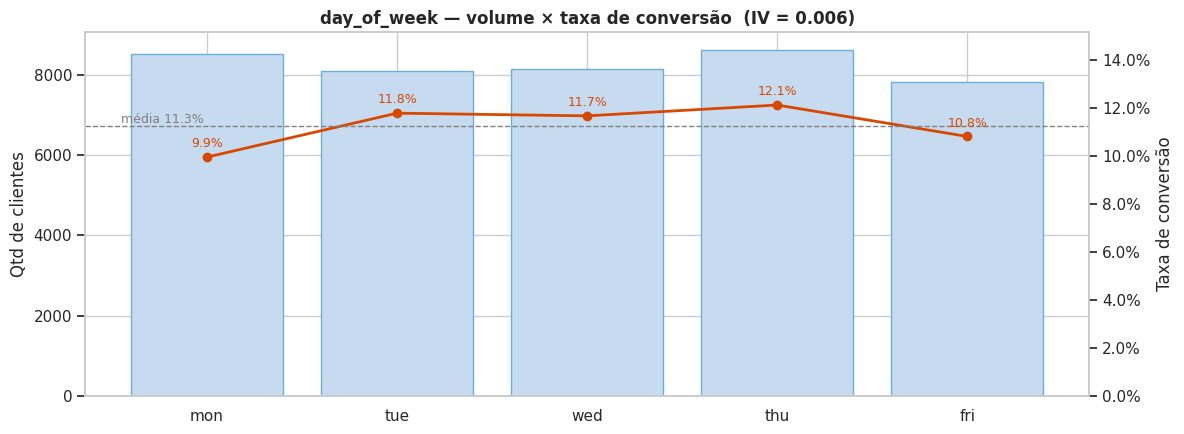

In [20]:
tab_day_of_week = analisar_categoria('day_of_week', rot=0)

### 4.10 `poutcome`

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
poutcome,,,,,,,
nonexistent,"35,563",86.3%,"3,141",8.8%,0.78,-0.270,0.0568
failure,"4,252",10.3%,605,14.2%,1.26,0.268,0.0082
success,"1,373",3.3%,894,65.1%,5.78,2.687,0.4828


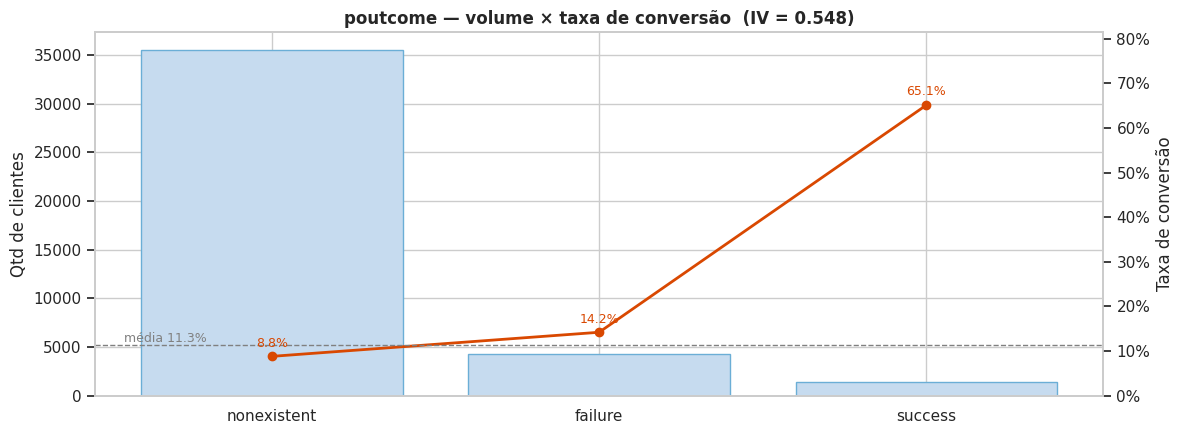

In [21]:
tab_poutcome = analisar_categoria('poutcome', rot=0)

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
AnoMes,,,,,,,
200805,"7,763",18.8%,240,3.1%,0.27,-1.379,0.2124
200806,"4,374",10.6%,188,4.3%,0.38,-1.037,0.0766
200807,"6,685",16.2%,407,6.1%,0.54,-0.671,0.0563
200808,"5,175",12.6%,271,5.2%,0.46,-0.830,0.0628
200810,67,0.2%,42,62.7%,5.56,2.575,0.0218
200811,"3,616",8.8%,190,5.3%,0.47,-0.826,0.0435
200812,10,0.0%,1,10.0%,0.89,0.218,0.0000
200903,282,0.7%,126,44.7%,3.97,1.851,0.0425
200904,"2,458",6.0%,442,18.0%,1.60,0.547,0.0220


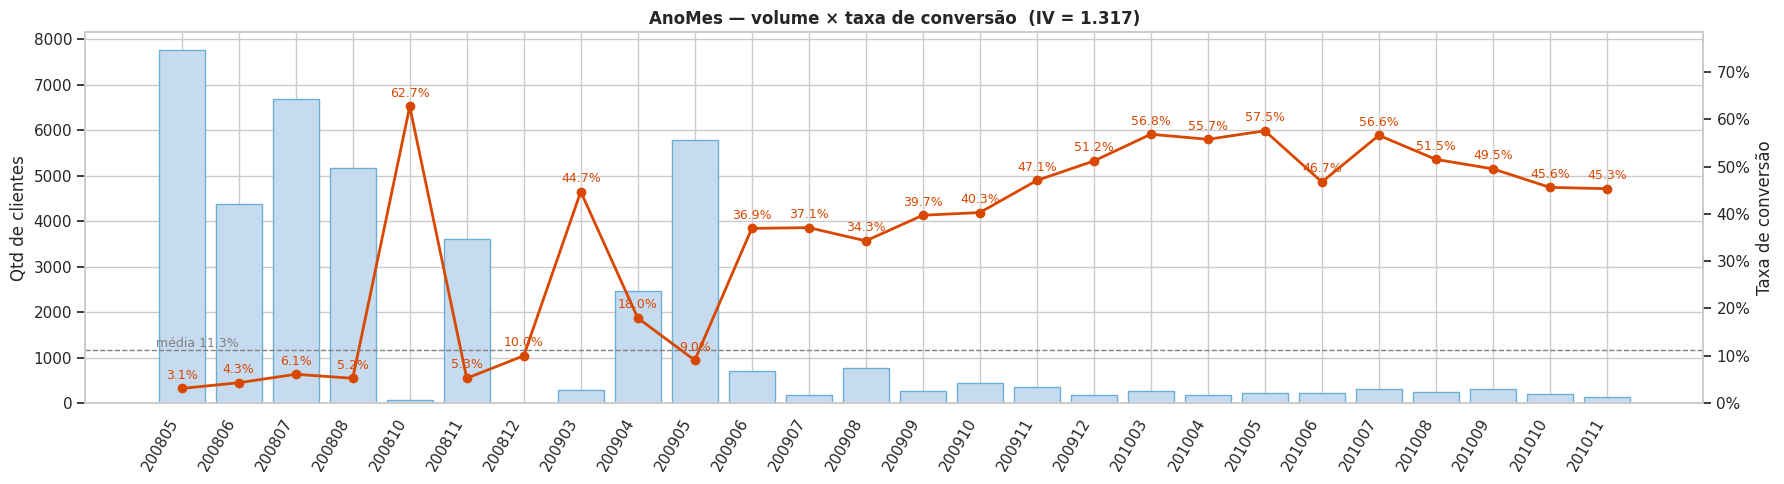

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
periodo_agrupado,,,,,,,
2008-05/06,"12,137",29.5%,428,3.5%,0.31,-1.244,0.2837
2008-07/08,"11,860",28.8%,678,5.7%,0.51,-0.738,0.1180
2008-10/12,"3,693",9.0%,233,6.3%,0.56,-0.632,0.0280
2009-03/05,"8,534",20.7%,"1,092",12.8%,1.14,0.145,0.0046
2009-06/08,"1,663",4.0%,594,35.7%,3.17,1.477,0.1460
2009-09/12,"1,243",3.0%,542,43.6%,3.87,1.807,0.1765
2010-03/06,879,2.1%,476,54.2%,4.81,2.230,0.2044
2010-07/11,"1,179",2.9%,597,50.6%,4.49,2.089,0.2357


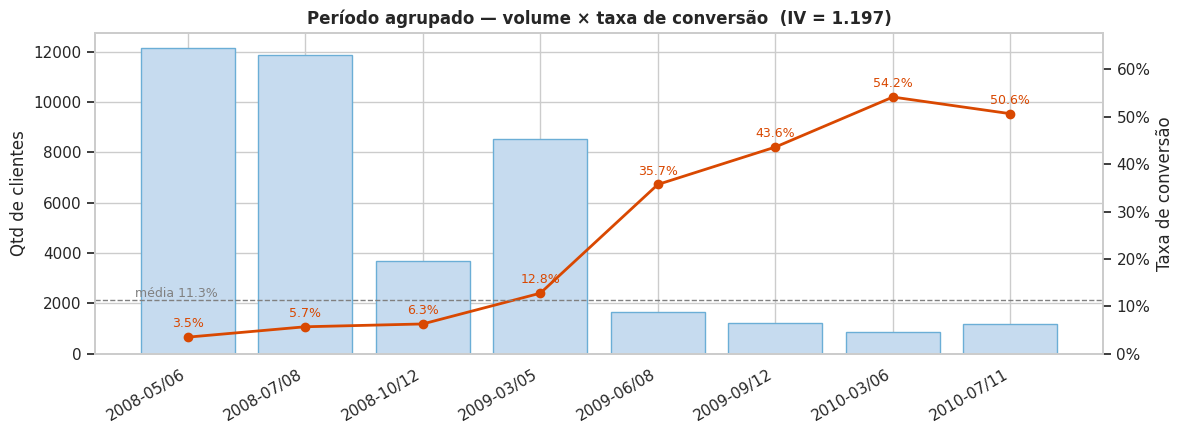

In [22]:
# ===== Volume x taxa de conversão por AnoMes e por período agrupado =====
MAPA_MES = {m: i for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun',
                                        'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], start=1)}
num_mes = df['month'].map(MAPA_MES)
df['AnoMes'] = (2008 + (num_mes.diff() < 0).cumsum()) * 100 + num_mes   # base em ordem cronológica

MAPA_PERIODO = {
    200805: '2008-05/06', 200806: '2008-05/06',
    200807: '2008-07/08', 200808: '2008-07/08',
    200810: '2008-10/12', 200811: '2008-10/12', 200812: '2008-10/12',
    200903: '2009-03/05', 200904: '2009-03/05', 200905: '2009-03/05',
    200906: '2009-06/08', 200907: '2009-06/08', 200908: '2009-06/08',
    200909: '2009-09/12', 200910: '2009-09/12', 200911: '2009-09/12', 200912: '2009-09/12',
    201003: '2010-03/06', 201004: '2010-03/06', 201005: '2010-03/06', 201006: '2010-03/06',
    201007: '2010-07/11', 201008: '2010-07/11', 201009: '2010-07/11', 201010: '2010-07/11', 201011: '2010-07/11',
}
df['periodo_agrupado'] = df['AnoMes'].map(MAPA_PERIODO)
assert df['periodo_agrupado'].notna().all(), 'Há AnoMes fora do MAPA_PERIODO'

# 1. Por AnoMes
tab_anomes = tabela_categoria(df, 'AnoMes').sort_index()
display(estilo(tab_anomes))
plot_volume_taxa(tab_anomes, 'AnoMes', rot=60, figsize=(18, 5))

# 2. Por período agrupado
tab_periodo_agr = tabela_categoria(df, 'periodo_agrupado').sort_index()
display(estilo(tab_periodo_agr))
plot_volume_taxa(tab_periodo_agr, 'Período agrupado', rot=30)

**Leitura (preencher após rodar):**
- Profissões/categorias que mais convertem: …
- `poutcome = success`: …
- `contact = cellular` vs `telephone`: …
- Meses com baixo volume e alta conversão (mar, set, out, dez): …

## 5. Estudo de público — variáveis numéricas e faixas

### 5.1 Distribuição por target
Histogramas sobrepostos (densidade) e boxplots separados por `y`.

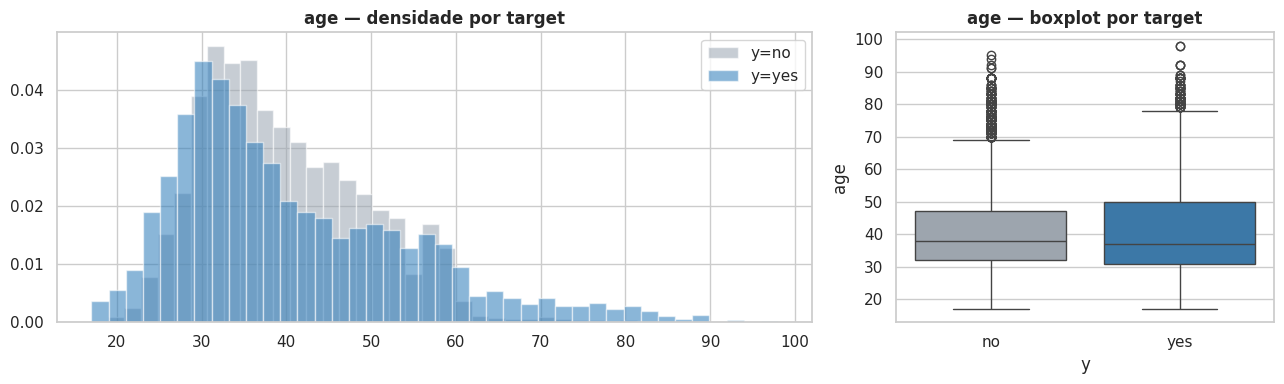

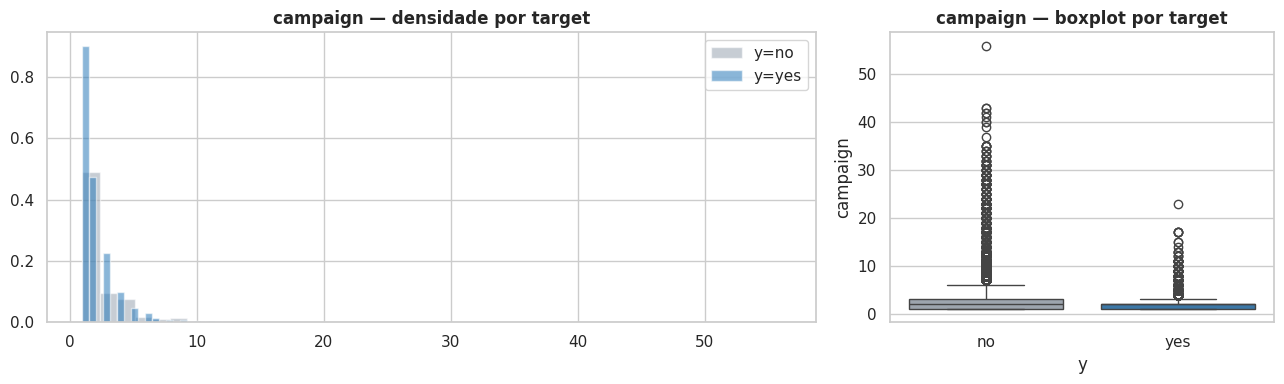

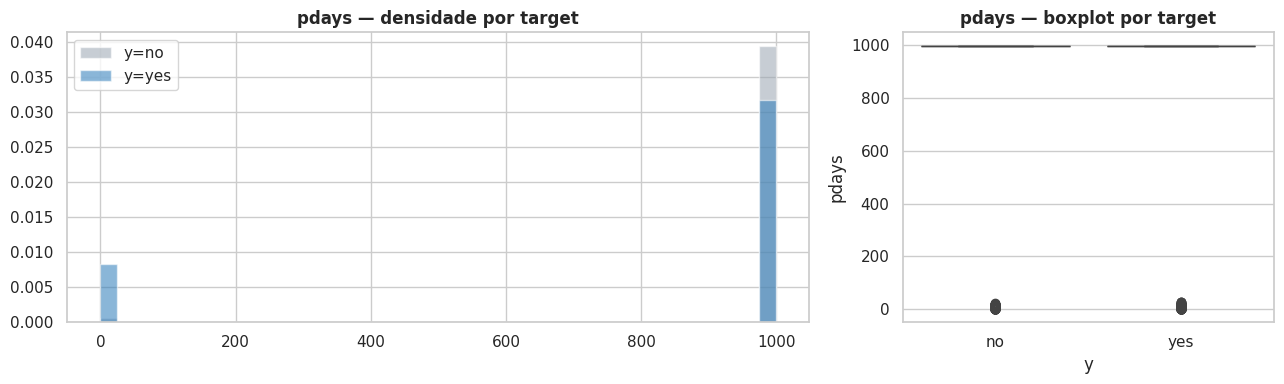

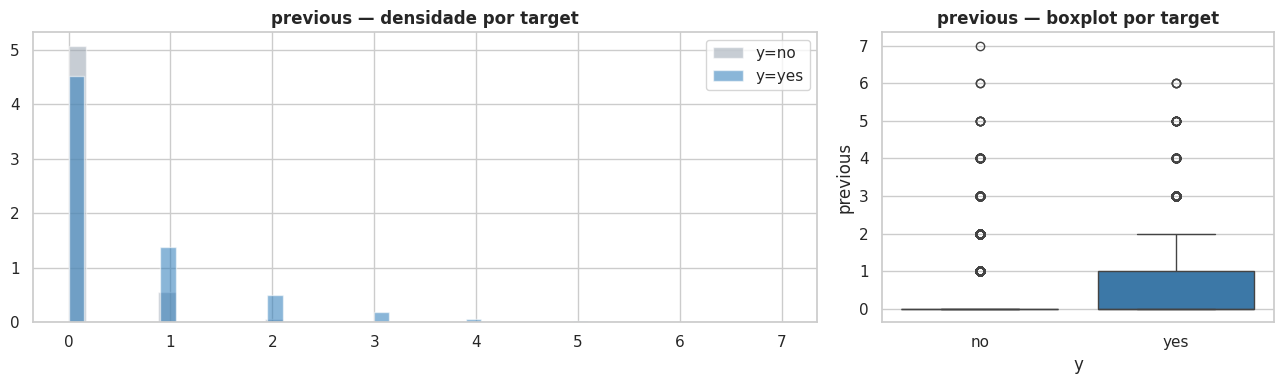

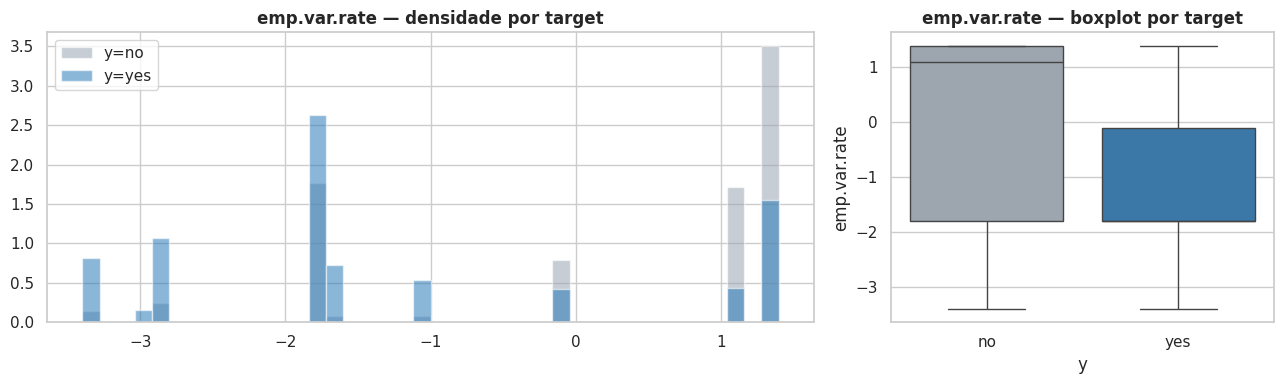

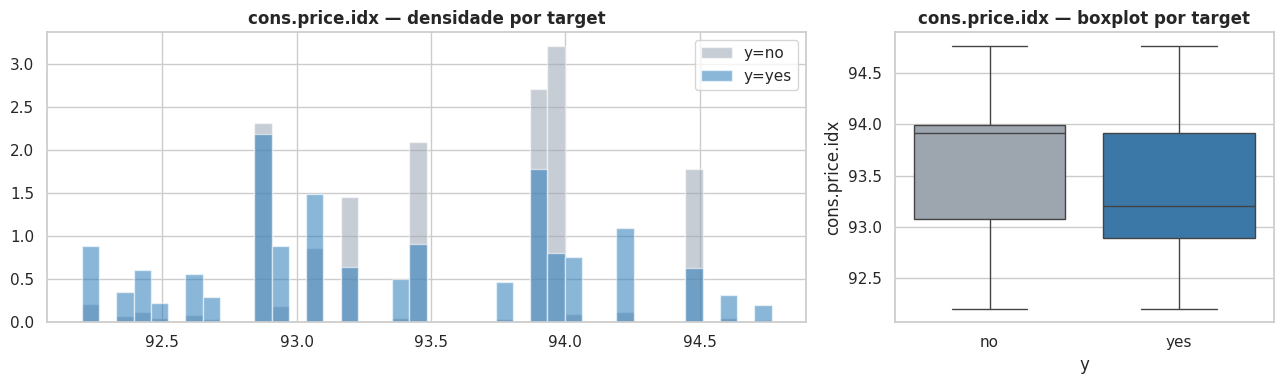

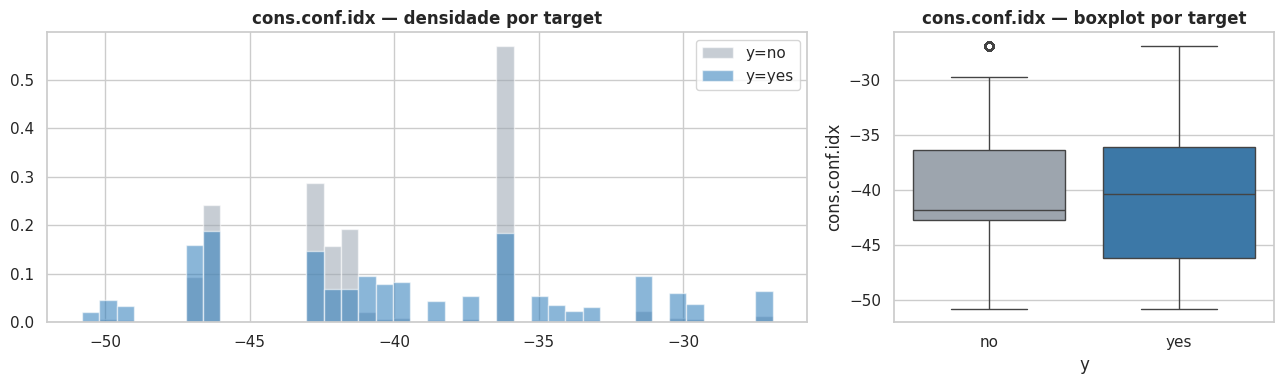

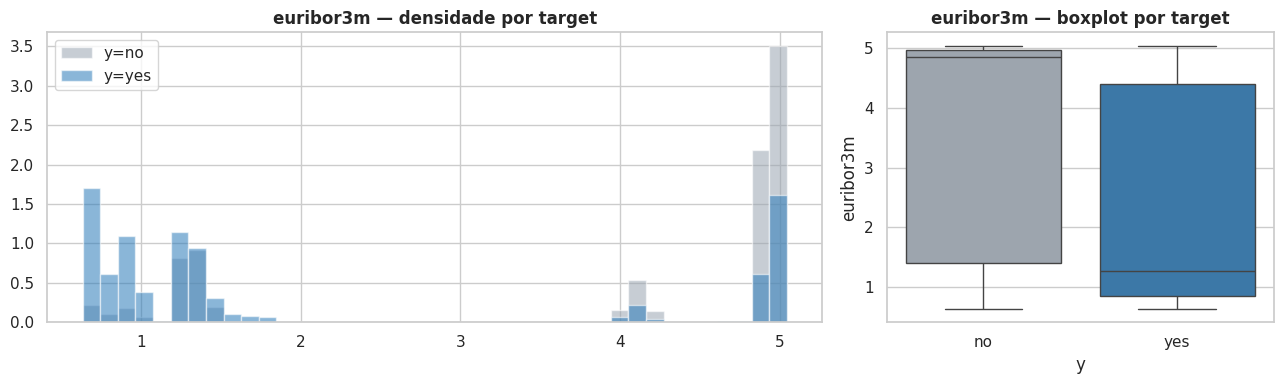

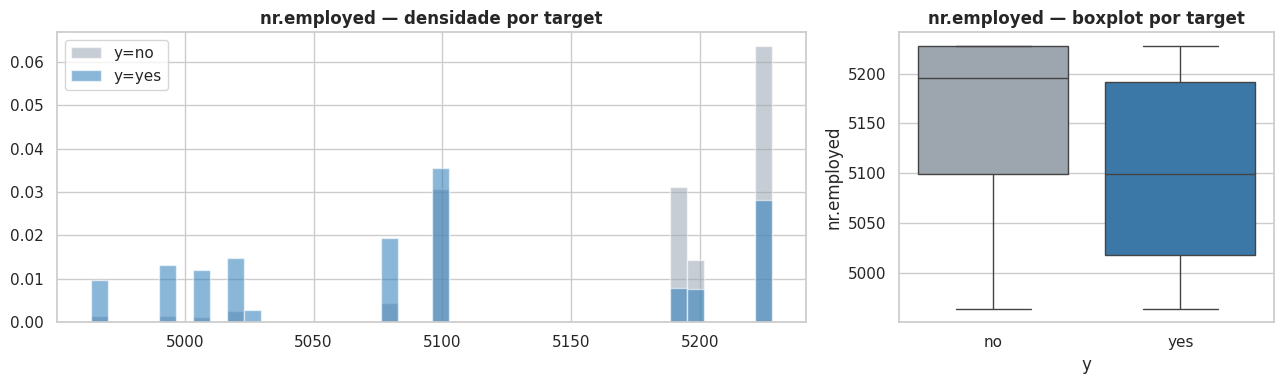

In [23]:
def plot_dist_num(col, bins=40):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
    for val, cor, nome in [(0, '#9aa5b1', 'no'), (1, '#2a7ab9', 'yes')]:
        axes[0].hist(df.loc[df[TARGET] == val, col], bins=bins, density=True, alpha=.55, color=cor, label=f'y={nome}')
    axes[0].legend(); axes[0].set_title(f'{col} — densidade por target')
    sns.boxplot(data=df, x='y', y=col, ax=axes[1], palette={'no': '#9aa5b1', 'yes': '#2a7ab9'}, order=['no', 'yes'])
    axes[1].set_title(f'{col} — boxplot por target')
    plt.tight_layout(); plt.show()

for c in COLS_NUM:
    plot_dist_num(c)

In [24]:
# Média/mediana das numéricas por target + teste Mann-Whitney
res = []
for c in COLS_NUM + COL_VAZAMENTO:
    a, b = df.loc[df[TARGET] == 0, c], df.loc[df[TARGET] == 1, c]
    res.append({'variavel': c, 'media_no': a.mean(), 'media_yes': b.mean(),
                'mediana_no': a.median(), 'mediana_yes': b.median(),
                'p_valor_mannwhitney': stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(res).set_index('variavel')

,media_no,media_yes,mediana_no,mediana_yes,p_valor_mannwhitney
variavel,,,,,
age,39.9112,40.9131,38.0000,37.0000,0.0161
campaign,2.6331,2.0517,2.0000,2.0000,0.0000
pdays,984.1139,792.0356,999.0000,999.0000,0.0000
previous,0.1324,0.4927,0.0000,0.0000,0.0000
emp.var.rate,0.2489,-1.2334,1.1000,-1.8000,0.0000
cons.price.idx,93.6038,93.3544,93.9180,93.2000,0.0000
cons.conf.idx,-40.5931,-39.7898,-41.8000,-40.4000,0.0000
euribor3m,3.8115,2.1231,4.8570,1.2660,0.0000
nr.employed,"5,176.1666","5,095.1160","5,195.8000","5,099.1000",0.0000


### 5.2 Faixas de idade

Duas visões: **faixas de negócio** (fáceis de comunicar) e **faixas por quantil** (decis, mesmo volume por faixa).

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
faixa_idade,,,,,,,
17-24,"1,068",2.6%,256,24.0%,2.13,0.911,0.0301
25-34,"13,686",33.2%,"1,666",12.2%,1.08,0.088,0.0027
35-44,"13,500",32.8%,"1,168",8.7%,0.77,-0.293,0.0251
45-54,"8,704",21.1%,753,8.7%,0.77,-0.293,0.0161
55-64,"3,567",8.7%,484,13.6%,1.20,0.213,0.0043
65+,663,1.6%,313,47.2%,4.19,1.952,0.1132


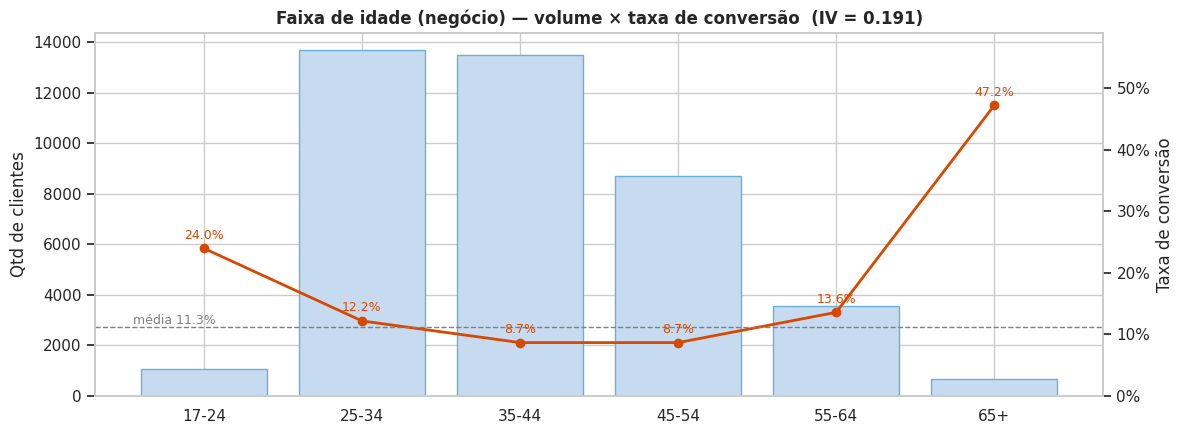

In [25]:
bins_idade = [0, 24, 34, 44, 54, 64, 120]
labels_idade = ['17-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['faixa_idade'] = pd.cut(df['age'], bins=bins_idade, labels=labels_idade)

tab_faixa_idade = tabela_categoria(df, 'faixa_idade')
display(estilo(tab_faixa_idade))
plot_volume_taxa(tab_faixa_idade, 'Faixa de idade (negócio)')

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_idade,,,,,,,
"(16.999, 28.0]","4,216",10.2%,736,17.5%,1.55,0.511,0.0324
"(28.0, 31.0]","5,114",12.4%,608,11.9%,1.06,0.062,0.0005
"(31.0, 33.0]","3,679",8.9%,394,10.7%,0.95,-0.056,0.0003
"(33.0, 35.0]","3,504",8.5%,351,10.0%,0.89,-0.130,0.0014
"(35.0, 38.0]","4,662",11.3%,434,9.3%,0.83,-0.212,0.0047
"(38.0, 41.0]","3,871",9.4%,311,8.0%,0.71,-0.372,0.0113
"(41.0, 45.0]","4,311",10.5%,348,8.1%,0.72,-0.367,0.0123
"(45.0, 49.0]","3,776",9.2%,289,7.7%,0.68,-0.425,0.0140
"(49.0, 55.0]","4,473",10.9%,428,9.6%,0.85,-0.181,0.0033


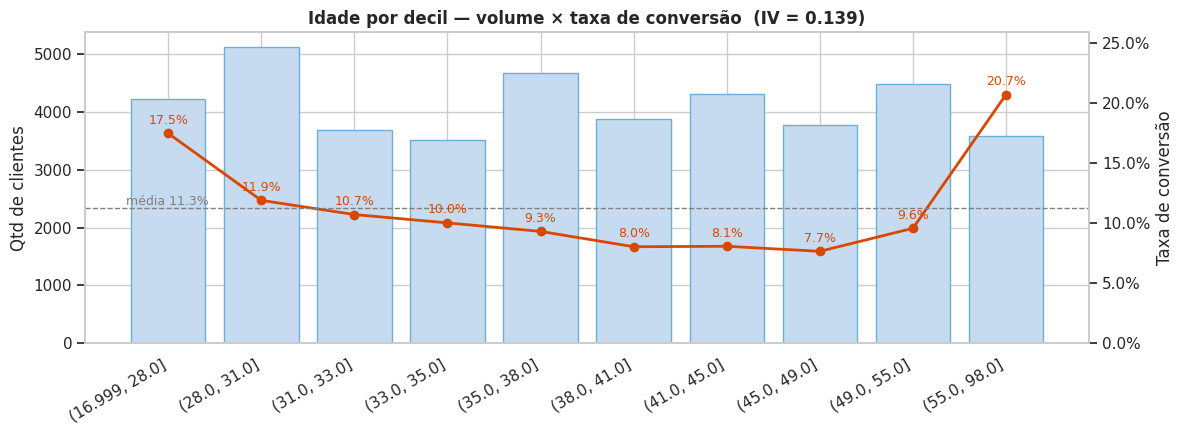

In [26]:
df['decil_idade'] = pd.qcut(df['age'], q=10, duplicates='drop')
tab_decil_idade = tabela_categoria(df, 'decil_idade')
display(estilo(tab_decil_idade))
plot_volume_taxa(tab_decil_idade, 'Idade por decil', rot=30)

### 5.3 Faixas de contato (`campaign`, `pdays`, `previous`)

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
faixa_campaign,,,,,,,
1,"17,642",42.8%,"2,300",13.0%,1.16,0.166,0.0126
2,"10,570",25.7%,"1,211",11.5%,1.02,0.019,0.0001
3,"5,341",13.0%,574,10.7%,0.95,-0.052,0.0003
4-5,"4,250",10.3%,369,8.7%,0.77,-0.288,0.0077
6-10,"2,516",6.1%,159,6.3%,0.56,-0.629,0.0190
11+,869,2.1%,27,3.1%,0.28,-1.358,0.0233


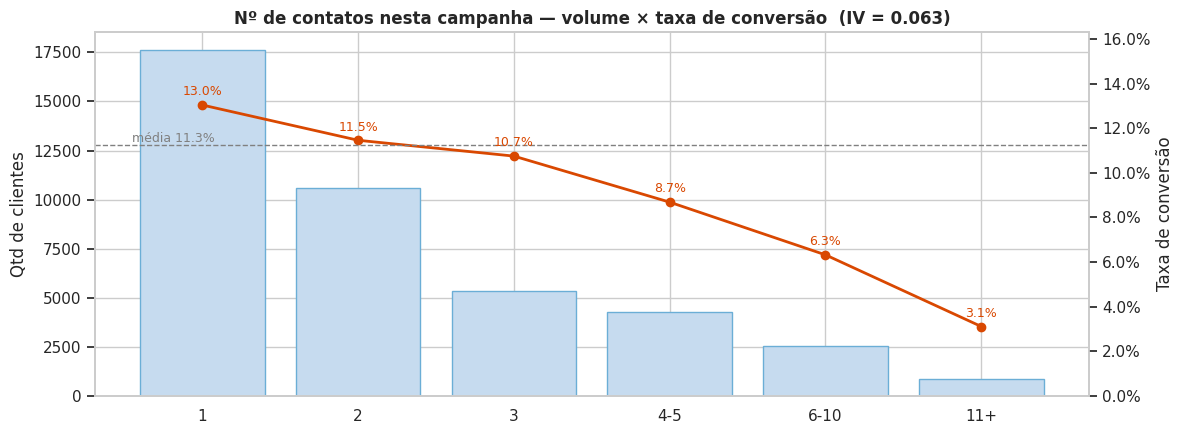

In [27]:
df['faixa_campaign'] = pd.cut(df['campaign'], bins=[0, 1, 2, 3, 5, 10, np.inf],
                              labels=['1', '2', '3', '4-5', '6-10', '11+'])
tab_faixa_campaign = tabela_categoria(df, 'faixa_campaign')
display(estilo(tab_faixa_campaign))
plot_volume_taxa(tab_faixa_campaign, 'Nº de contatos nesta campanha')

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
faixa_pdays,,,,,,,
0-3 dias,541,1.3%,353,65.2%,5.79,2.693,0.1912
4-7 dias,636,1.5%,421,66.2%,5.88,2.735,0.2323
8+ dias,338,0.8%,193,57.1%,5.07,2.349,0.0886
nunca contatado,"39,673",96.3%,"3,673",9.3%,0.82,-0.219,0.0423


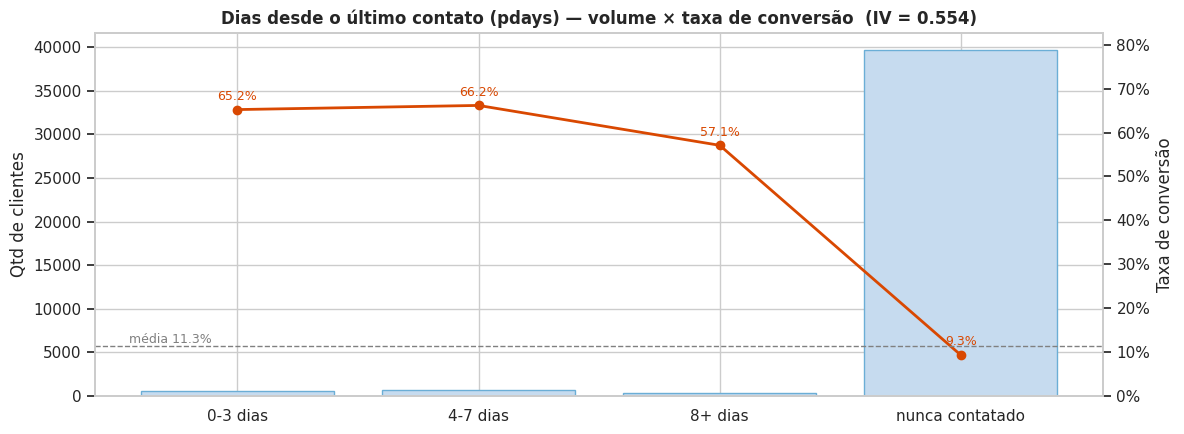

In [28]:
df['faixa_pdays'] = pd.cut(df['pdays'], bins=[-1, 3, 7, 998, 999],
                           labels=['0-3 dias', '4-7 dias', '8+ dias', 'nunca contatado'])
tab_faixa_pdays = tabela_categoria(df, 'faixa_pdays')
display(estilo(tab_faixa_pdays))
plot_volume_taxa(tab_faixa_pdays, 'Dias desde o último contato (pdays)')

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
faixa_previous,,,,,,,
0,"35,563",86.3%,"3,141",8.8%,0.78,-0.270,0.0568
1,"4,561",11.1%,967,21.2%,1.88,0.751,0.0828
2+,"1,064",2.6%,532,50.0%,4.44,2.064,0.2068


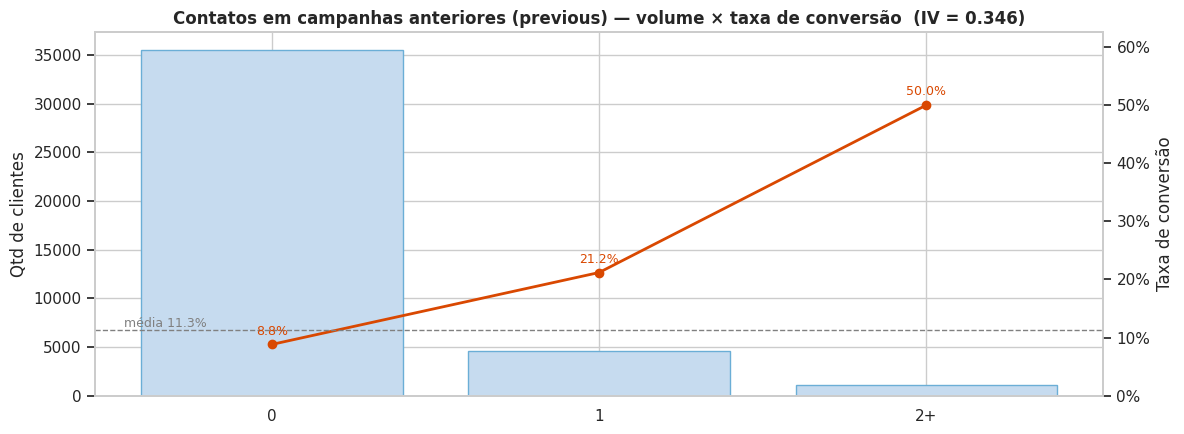

In [29]:
df['faixa_previous'] = pd.cut(df['previous'], bins=[-1, 0, 1, np.inf], labels=['0', '1', '2+'])
tab_faixa_previous = tabela_categoria(df, 'faixa_previous')
display(estilo(tab_faixa_previous))
plot_volume_taxa(tab_faixa_previous, 'Contatos em campanhas anteriores (previous)')

### 5.4 Indicadores macroeconômicos (decis)

Lembrete: são indicadores do **país no momento do contato**, não do cliente. `nr.employed` é o nº de empregados na economia, não da empresa do cliente.

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_emp.var.rate,,,,,,,
"(-3.401, -1.8]","12,090",29.4%,"2,597",21.5%,1.91,0.768,0.2303
"(-1.8, -1.7]",773,1.9%,403,52.1%,4.63,2.149,0.1651
"(-1.7, -0.1]","4,328",10.5%,534,12.3%,1.10,0.104,0.0012
"(-0.1, 1.1]","7,763",18.8%,240,3.1%,0.27,-1.379,0.2124
"(1.1, 1.4]","16,234",39.4%,866,5.3%,0.47,-0.812,0.1898


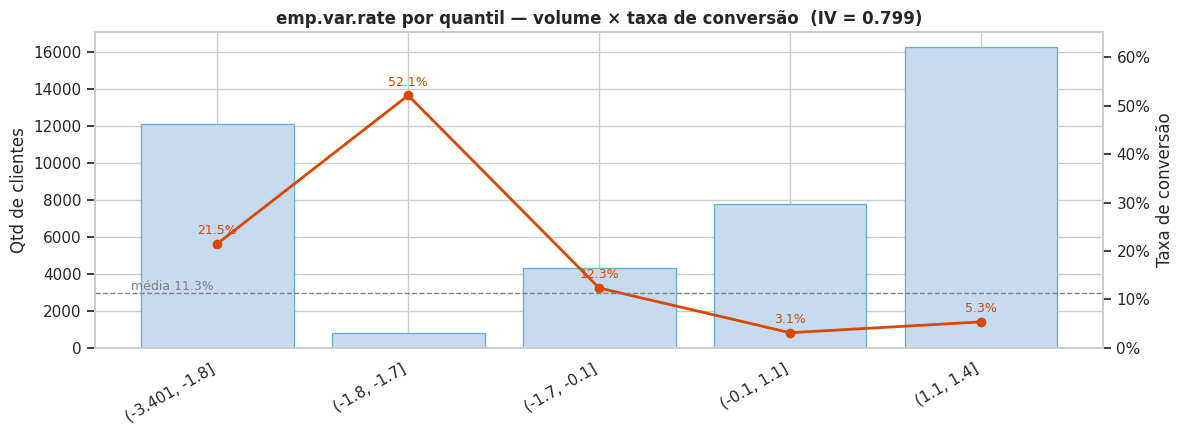

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_cons.price.idx,,,,,,,
"(92.19999999999999, 92.893]","8,277",20.1%,"1,523",18.4%,1.63,0.575,0.0825
"(92.893, 93.2]","6,789",16.5%,896,13.2%,1.17,0.181,0.0058
"(93.2, 93.444]","5,439",13.2%,421,7.7%,0.69,-0.413,0.0192
"(93.444, 93.749]",174,0.4%,97,55.7%,4.95,2.293,0.0433
"(93.749, 93.918]","6,964",16.9%,571,8.2%,0.73,-0.351,0.0182
"(93.918, 93.994]","7,763",18.8%,240,3.1%,0.27,-1.379,0.2124
"(93.994, 94.465]","5,450",13.2%,741,13.6%,1.21,0.215,0.0067
"(94.465, 94.767]",332,0.8%,151,45.5%,4.04,1.883,0.0521


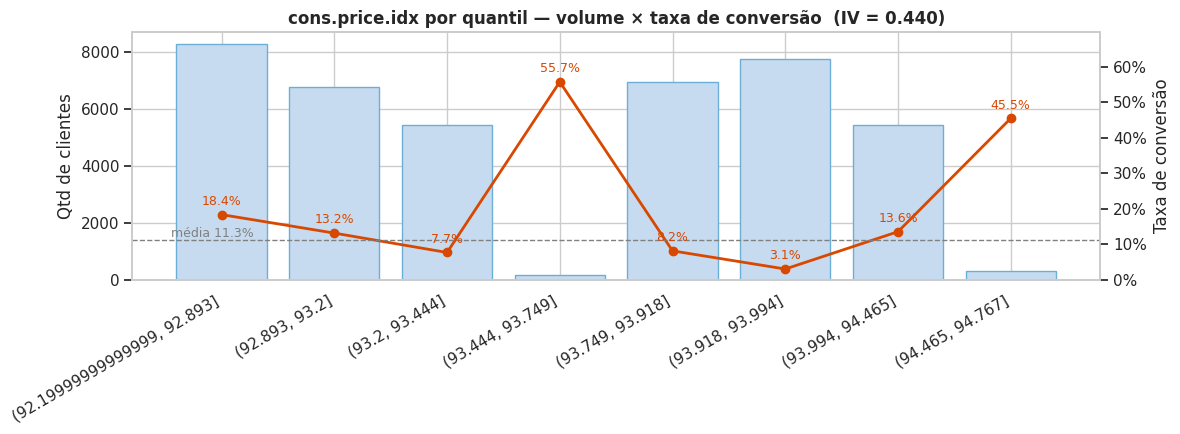

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_cons.conf.idx,,,,,,,
"(-50.800999999999995, -46.2]","8,866",21.5%,"1,243",14.0%,1.24,0.251,0.0149
"(-46.2, -42.7]","6,695",16.3%,408,6.1%,0.54,-0.670,0.0563
"(-42.7, -42.0]","3,616",8.8%,190,5.3%,0.47,-0.826,0.0435
"(-42.0, -41.8]","4,374",10.6%,188,4.3%,0.38,-1.037,0.0766
"(-41.8, -40.0]","1,305",3.2%,604,46.3%,4.11,1.915,0.2127
"(-40.0, -36.4]","8,528",20.7%,617,7.2%,0.64,-0.487,0.0406
"(-36.4, -36.1]","5,175",12.6%,271,5.2%,0.46,-0.830,0.0628
"(-36.1, -26.9]","2,629",6.4%,"1,119",42.6%,3.78,1.764,0.3527


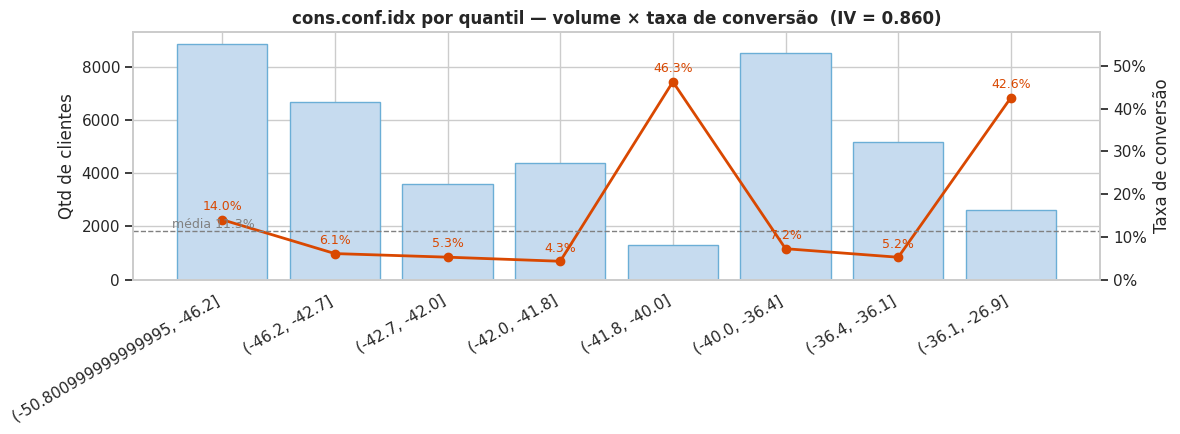

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_euribor3m,,,,,,,
"(0.633, 1.046]","4,128",10.0%,"1,895",45.9%,4.07,1.900,0.6599
"(1.046, 1.299]","4,508",10.9%,666,14.8%,1.31,0.312,0.0120
"(1.299, 1.41]","3,926",9.5%,494,12.6%,1.12,0.126,0.0016
"(1.41, 4.191]","4,504",10.9%,415,9.2%,0.82,-0.223,0.0050
"(4.191, 4.857]","4,989",12.1%,156,3.1%,0.28,-1.366,0.1346
"(4.857, 4.864]","3,457",8.4%,150,4.3%,0.39,-1.026,0.0596
"(4.864, 4.96]","3,983",9.7%,235,5.9%,0.52,-0.704,0.0365
"(4.96, 4.962]","4,515",11.0%,234,5.2%,0.46,-0.841,0.0560
"(4.962, 4.964]","3,662",8.9%,181,4.9%,0.44,-0.890,0.0500


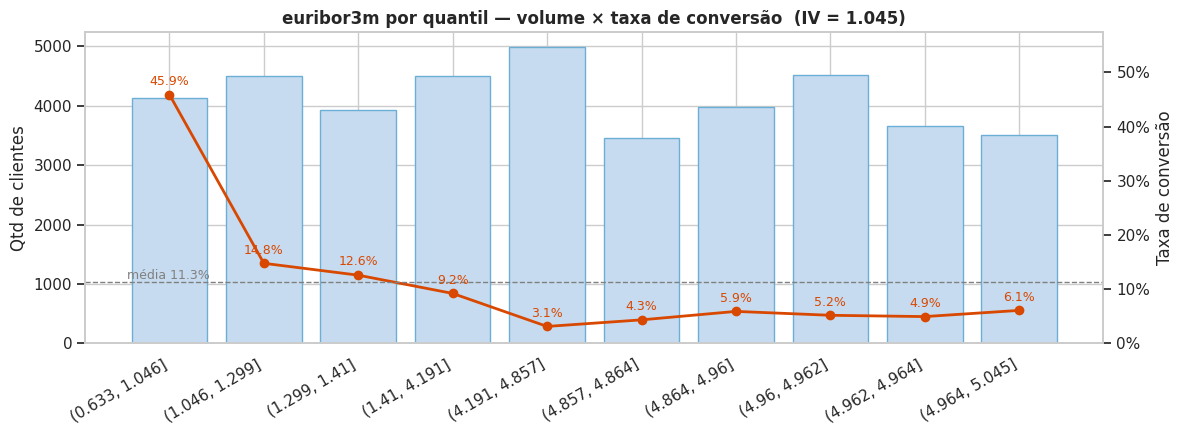

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_nr.employed,,,,,,,
"(4963.599, 5076.2]","4,964",12.1%,"2,209",44.5%,3.95,1.843,0.7386
"(5076.2, 5099.1]","8,534",20.7%,"1,092",12.8%,1.14,0.145,0.0046
"(5099.1, 5191.0]","7,773",18.9%,241,3.1%,0.28,-1.376,0.2120
"(5191.0, 5195.8]","3,683",8.9%,232,6.3%,0.56,-0.634,0.0281
"(5195.8, 5228.1]","16,234",39.4%,866,5.3%,0.47,-0.812,0.1898


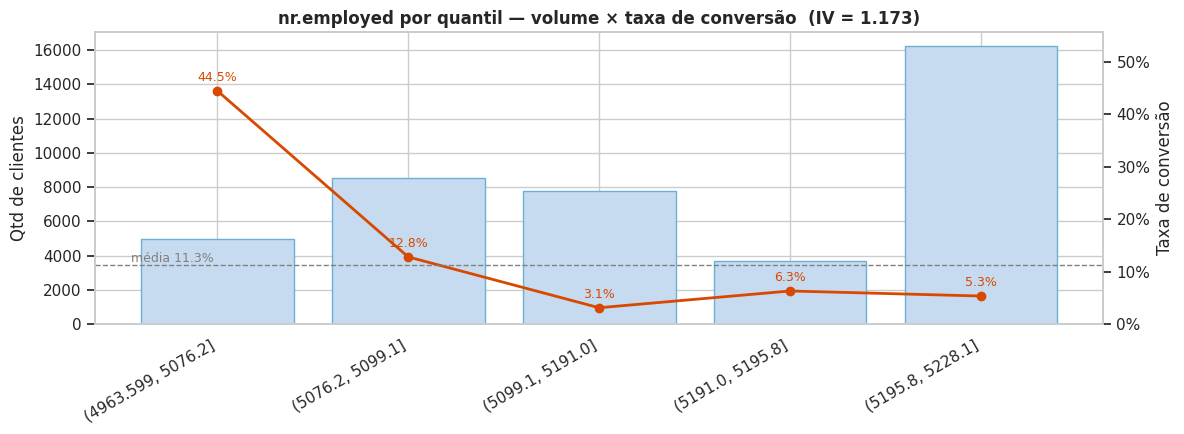

In [30]:
for c in COLS_MACRO:
    col_faixa = f'decil_{c}'
    df[col_faixa] = pd.qcut(df[c], q=10, duplicates='drop')
    tab = tabela_categoria(df, col_faixa)
    display(estilo(tab))
    plot_volume_taxa(tab, f'{c} por quantil', rot=30)

In [31]:
# Quantos valores distintos as macro têm? (são poucas "fotos" do cenário)
df[COLS_MACRO].nunique().to_frame('valores_distintos')

,valores_distintos
emp.var.rate,10
cons.price.idx,26
cons.conf.idx,26
euribor3m,316
nr.employed,11


## 6. `duration` — por que fica fora do modelo

A duração da ligação só é conhecida **depois** do contato e quase define o resultado (`duration = 0` → `y = no`). Mostramos o efeito apenas para registrar o vazamento.

,qtd,pct_publico,conversoes,taxa_conversao,lift,woe,iv
decil_duration,,,,,,,
"(-0.001, 59.0]","4,181",10.2%,1,0.0%,0.00,-5.869,0.6694
"(59.0, 89.0]","4,207",10.2%,43,1.0%,0.09,-2.498,0.2612
"(89.0, 116.0]","3,987",9.7%,107,2.7%,0.24,-1.522,0.1264
"(116.0, 146.0]","4,152",10.1%,157,3.8%,0.34,-1.170,0.0882
"(146.0, 180.0]","4,178",10.1%,256,6.1%,0.54,-0.664,0.0345
"(180.0, 222.0]","4,096",9.9%,346,8.4%,0.75,-0.318,0.0089
"(222.0, 280.0]","4,062",9.9%,463,11.4%,1.01,0.014,0.0000
"(280.0, 368.0]","4,103",10.0%,554,13.5%,1.20,0.207,0.0046
"(368.0, 551.0]","4,118",10.0%,824,20.0%,1.78,0.679,0.0594


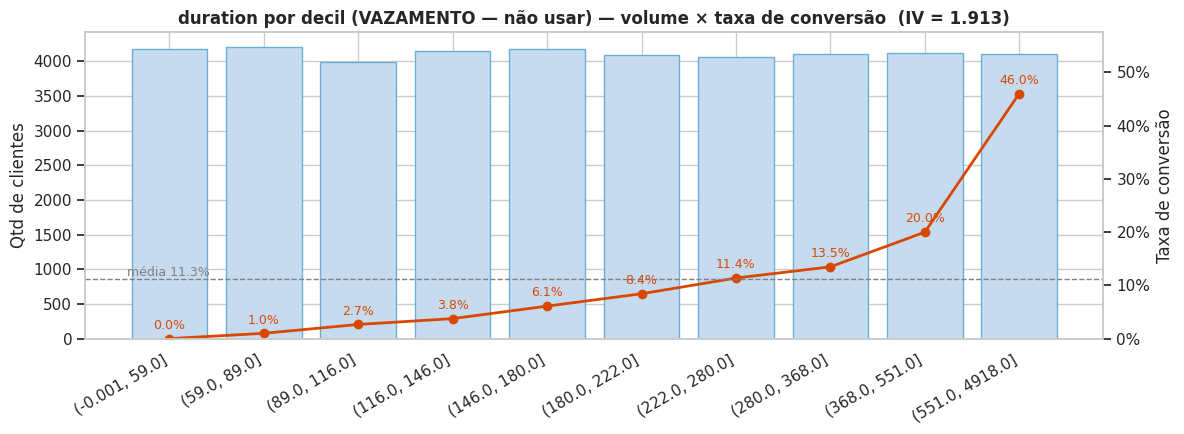

IV de duration: 1.913  → muito acima de 0,5: sinal clássico de vazamento
Conversão quando duration == 0: 0.0% (n = 4)


In [32]:
df['decil_duration'] = pd.qcut(df['duration'], q=10, duplicates='drop')
tab_dur = tabela_categoria(df, 'decil_duration')
display(estilo(tab_dur))
plot_volume_taxa(tab_dur, 'duration por decil (VAZAMENTO — não usar)', rot=30)
print(f"IV de duration: {tab_dur['iv'].sum():.3f}  → muito acima de 0,5: sinal clássico de vazamento")
print(f"Conversão quando duration == 0: {df.loc[df['duration'] == 0, TARGET].mean():.1%} (n = {(df['duration'] == 0).sum()})")

## 7. Correlações

### 7.1 Pearson e Spearman entre numéricas
`pdays` com 999 distorce a correlação linear; usamos uma versão tratada (`pdays_tratado`, 999 → NaN) ao lado do flag `flag_nunca_contatado`.

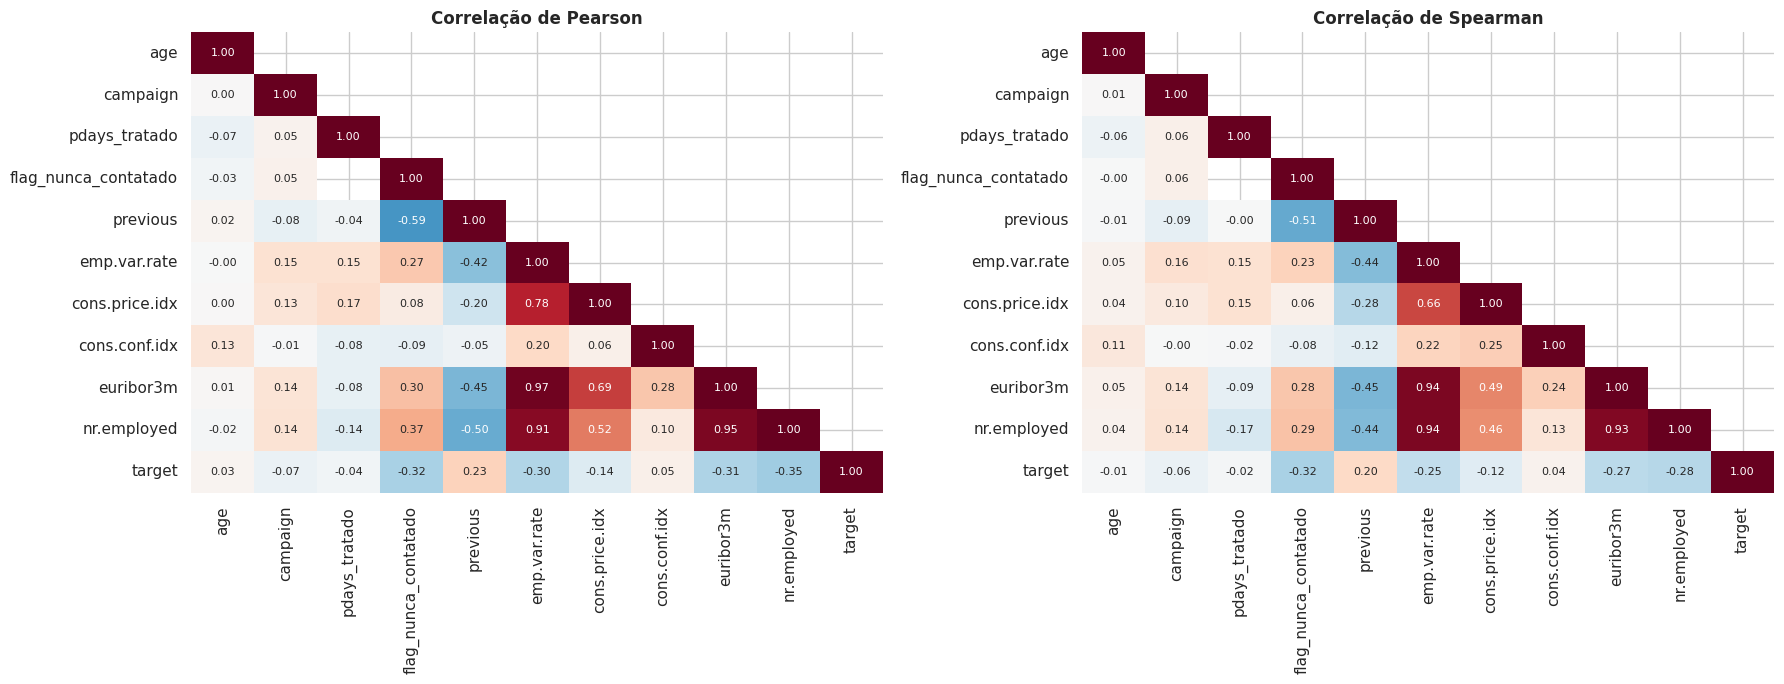

In [33]:
df['flag_nunca_contatado'] = (df['pdays'] == 999).astype(int)
df['pdays_tratado'] = df['pdays'].replace(999, np.nan)

cols_corr = ['age', 'campaign', 'pdays_tratado', 'flag_nunca_contatado', 'previous'] + COLS_MACRO + [TARGET]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, metodo in zip(axes, ['pearson', 'spearman']):
    corr = df[cols_corr].corr(method=metodo)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                ax=ax, cbar=False, annot_kws={'size': 8})
    ax.set_title(f'Correlação de {metodo.capitalize()}')
plt.tight_layout(); plt.show()

In [34]:
# Pares com |correlação de Pearson| > 0,7 (candidatos a multicolinearidade)
corr = df[cols_corr].drop(columns=TARGET).corr()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('pearson').reset_index()
             .rename(columns={'level_0': 'var_1', 'level_1': 'var_2'}))
pares[pares['pearson'].abs() > 0.7].sort_values('pearson', key=abs, ascending=False)

,var_1,var_2,pearson
36,emp.var.rate,euribor3m,0.9722
43,euribor3m,nr.employed,0.9452
37,emp.var.rate,nr.employed,0.9070
34,emp.var.rate,cons.price.idx,0.7753


### 7.2 Correlação das numéricas com o target
Pearson com `target` binário = **correlação ponto-bisserial**.

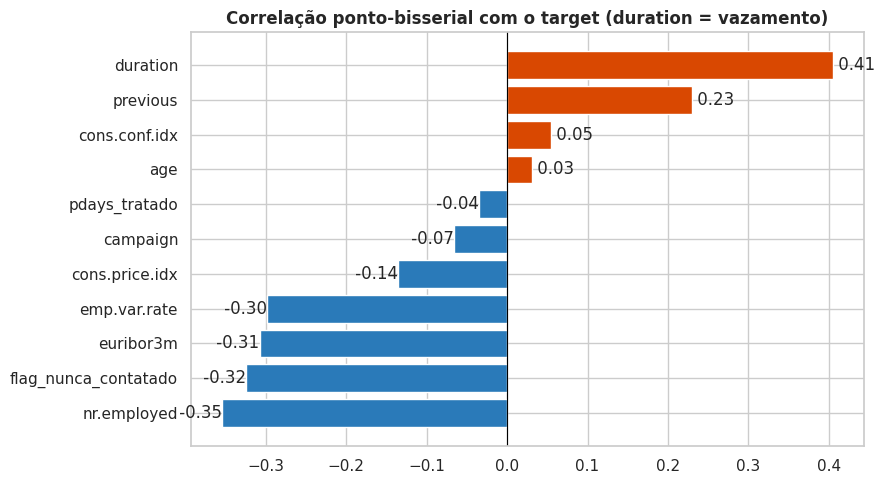

,variavel,pearson_pb,spearman,p_valor,n
10,duration,0.4053,0.3488,0.0000,41188
9,nr.employed,-0.3547,-0.2840,0.0000,41188
3,flag_nunca_contatado,-0.3249,-0.3249,0.0000,41188
8,euribor3m,-0.3078,-0.2668,0.0000,41188
5,emp.var.rate,-0.2983,-0.2475,0.0000,41188
4,previous,0.2302,0.2009,0.0000,41188
6,cons.price.idx,-0.1362,-0.1222,0.0000,41188
1,campaign,-0.0664,-0.0637,0.0000,41188
7,cons.conf.idx,0.0549,0.0412,0.0000,41188
2,pdays_tratado,-0.0352,-0.0223,0.1706,1515


In [35]:
corr_target = []
for c in ['age', 'campaign', 'pdays_tratado', 'flag_nunca_contatado', 'previous'] + COLS_MACRO + COL_VAZAMENTO:
    s = df[[c, TARGET]].dropna()
    r, p = stats.pointbiserialr(s[TARGET], s[c])
    rho, _ = stats.spearmanr(s[c], s[TARGET])
    corr_target.append({'variavel': c, 'pearson_pb': r, 'spearman': rho, 'p_valor': p, 'n': len(s)})
corr_target = pd.DataFrame(corr_target).sort_values('pearson_pb', key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
s = corr_target.set_index('variavel')['pearson_pb'].sort_values()
ax.barh(s.index, s.values, color=['#d94801' if v > 0 else '#2a7ab9' for v in s.values])
for i, v in enumerate(s.values):
    ax.text(v, i, f' {v:.2f}', va='center', ha='left' if v > 0 else 'right')
ax.axvline(0, color='black', lw=.8)
ax.set_title('Correlação ponto-bisserial com o target (duration = vazamento)')
plt.tight_layout(); plt.show()
corr_target

### 7.3 Cramér's V — associação entre categóricas (e com o target)

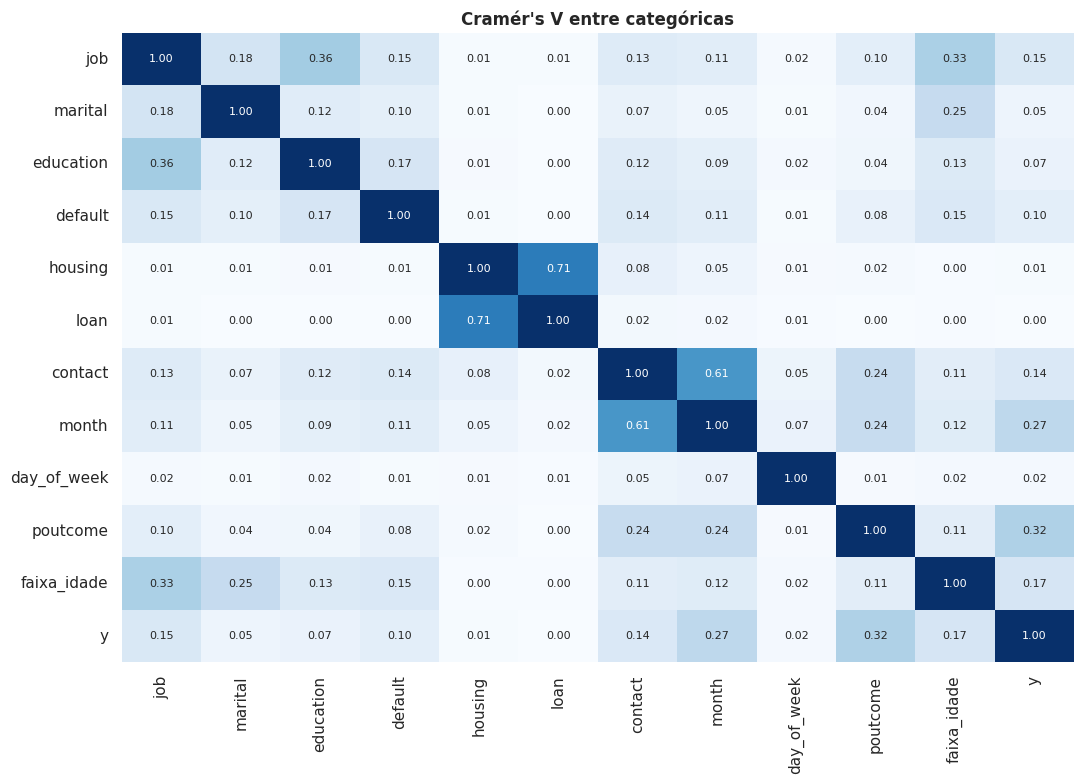

,cramers_v_com_y
poutcome,0.3204
month,0.2740
faixa_idade,0.1711
job,0.1519
contact,0.1447
default,0.0991
education,0.0672
marital,0.0539
day_of_week,0.0232
housing,0.0095


In [36]:
def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))

cols_cv = COLS_CAT + ['faixa_idade', 'y']
mat_cv = pd.DataFrame(index=cols_cv, columns=cols_cv, dtype=float)
for a in cols_cv:
    for b in cols_cv:
        mat_cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

plt.figure(figsize=(11, 8))
sns.heatmap(mat_cv, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, annot_kws={'size': 8})
plt.title("Cramér's V entre categóricas"); plt.tight_layout(); plt.show()

mat_cv['y'].drop('y').sort_values(ascending=False).to_frame("cramers_v_com_y")

## 8. Ranking de IV (poder de separação)

Todas as categóricas originais + as faixas criadas nas seções 5 e 6.

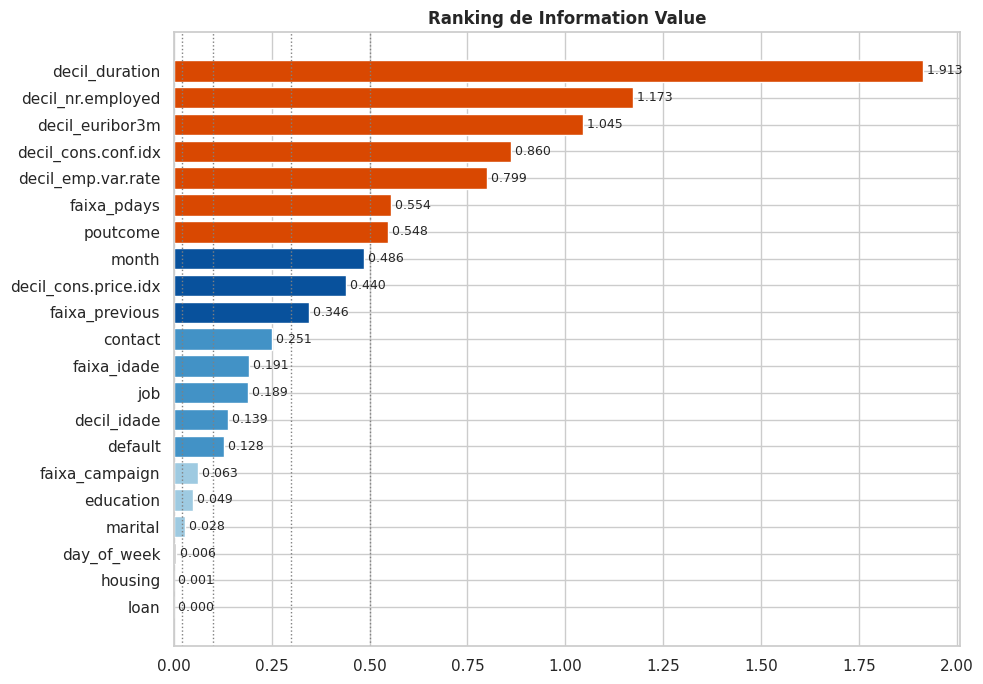

,iv,poder
decil_duration,1.9127,"suspeita (>0,5)"
decil_nr.employed,1.1731,"suspeita (>0,5)"
decil_euribor3m,1.0447,"suspeita (>0,5)"
decil_cons.conf.idx,0.8601,"suspeita (>0,5)"
decil_emp.var.rate,0.7988,"suspeita (>0,5)"
faixa_pdays,0.5544,"suspeita (>0,5)"
poutcome,0.5478,"suspeita (>0,5)"
month,0.4857,forte
decil_cons.price.idx,0.4401,forte
faixa_previous,0.3463,forte


In [37]:
def faixa_iv(iv):
    if iv < 0.02: return 'inútil'
    if iv < 0.1:  return 'fraca'
    if iv < 0.3:  return 'média'
    if iv < 0.5:  return 'forte'
    return 'suspeita (>0,5)'

cols_iv = COLS_CAT + ['faixa_idade', 'decil_idade', 'faixa_campaign', 'faixa_pdays', 'faixa_previous'] \
          + [f'decil_{c}' for c in COLS_MACRO] + ['decil_duration']
ranking_iv = pd.DataFrame({'iv': {c: tabela_categoria(df, c)['iv'].sum() for c in cols_iv}}) \
               .sort_values('iv', ascending=False)
ranking_iv['poder'] = ranking_iv['iv'].apply(faixa_iv)

fig, ax = plt.subplots(figsize=(10, 7))
s = ranking_iv['iv'].sort_values()
cores = ['#bdbdbd' if v < .02 else '#9ecae1' if v < .1 else '#4292c6' if v < .3 else '#08519c' if v < .5 else '#d94801'
         for v in s.values]
ax.barh(s.index, s.values, color=cores)
for i, v in enumerate(s.values):
    ax.text(v, i, f' {v:.3f}', va='center', fontsize=9)
for lim in [.02, .1, .3, .5]:
    ax.axvline(lim, ls=':', color='grey', lw=1)
ax.set_title('Ranking de Information Value')
plt.tight_layout(); plt.show()
ranking_iv

## 9. Visão temporal — cenário macro × conversão

A base está em **ordem cronológica** (mai/2008 → nov/2010) mas não traz o ano. Reconstruímos um índice de período detectando a troca de mês ao longo das linhas.

,qtd,taxa_conversao,euribor3m,nr_employed,emp_var_rate
periodo,,,,,
2008-05,"7,763",3.1%,4.857663,5191.000000,1.100000
2008-06,"4,374",4.3%,4.931639,5228.100000,1.400000
2008-07,"6,685",6.1%,4.961587,5228.100000,1.400000
2008-08,"5,175",5.2%,4.964804,5228.100000,1.400000
2008-10,67,62.7%,4.923776,5195.800000,-0.100000
2008-11,"3,616",5.3%,4.114895,5195.800000,-0.100000
2008-12,10,10.0%,3.493400,5176.300000,-0.200000
2009-03,282,44.7%,1.646220,5099.100000,-1.800000
2009-04,"2,458",18.0%,1.411722,5099.100000,-1.800000


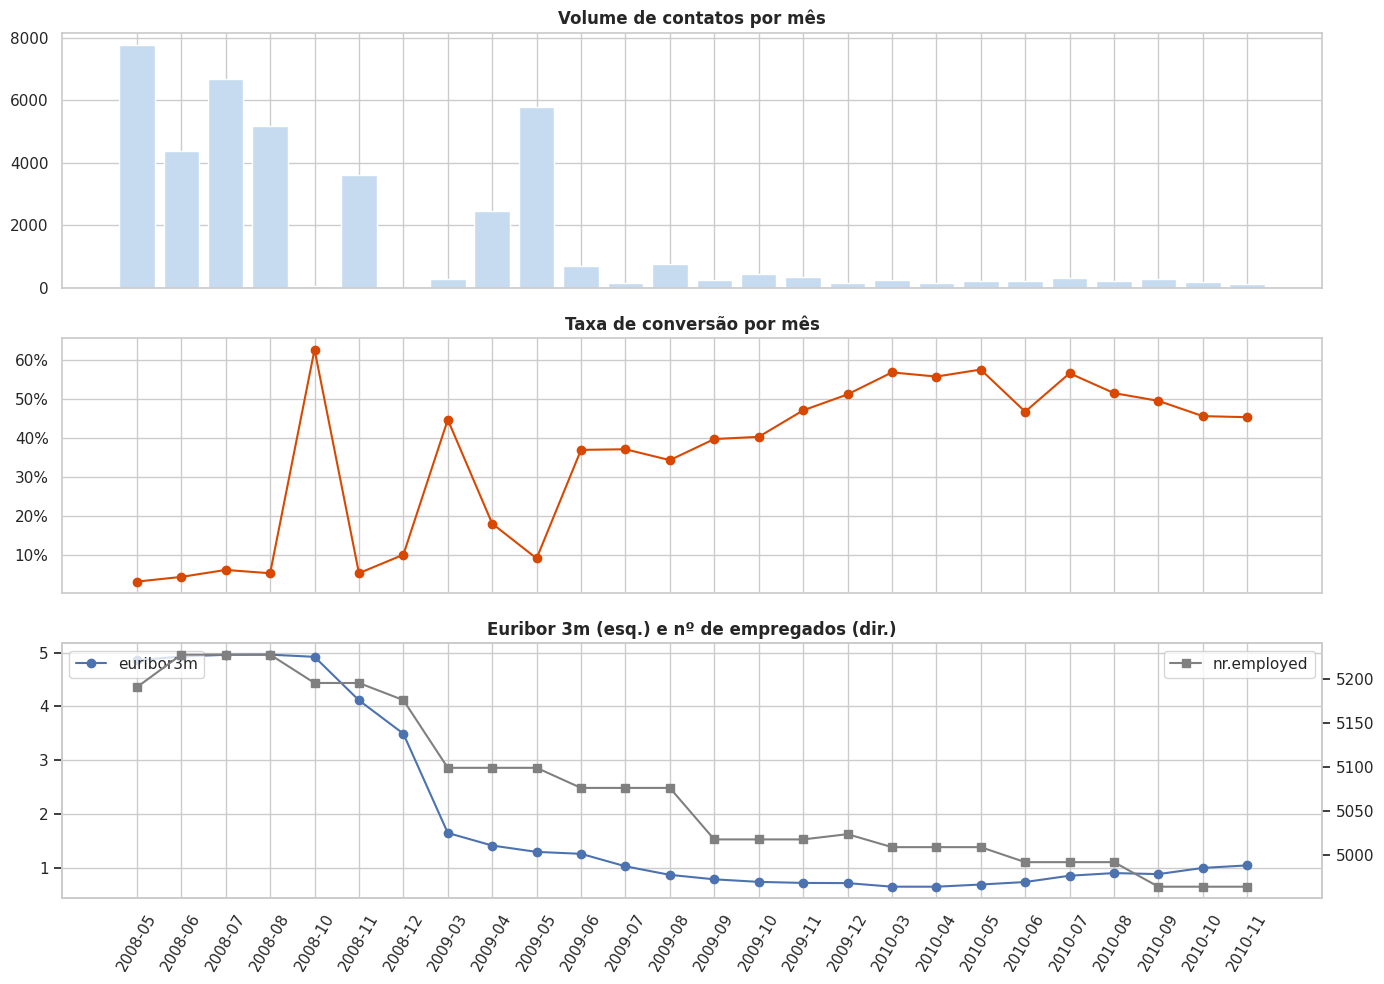

In [38]:
MAPA_MES = {m: i for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], 1)}
num_mes = df['month'].map(MAPA_MES)
virada_ano = (num_mes.diff() < 0).cumsum()          # mês "voltou" → novo ano
df['ano'] = 2008 + virada_ano
df['periodo'] = df['ano'].astype(str) + '-' + num_mes.astype(str).str.zfill(2)

temporal = df.groupby('periodo').agg(qtd=(TARGET, 'size'), taxa_conversao=(TARGET, 'mean'),
                                     euribor3m=('euribor3m', 'mean'), nr_employed=('nr.employed', 'mean'),
                                     emp_var_rate=('emp.var.rate', 'mean'))
display(temporal.style.format({'qtd': '{:,.0f}', 'taxa_conversao': '{:.1%}'}))

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].bar(temporal.index, temporal['qtd'], color='#c6dbef'); axes[0].set_title('Volume de contatos por mês')
axes[1].plot(temporal.index, temporal['taxa_conversao'], marker='o', color='#d94801')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title('Taxa de conversão por mês')
axes[2].plot(temporal.index, temporal['euribor3m'], marker='o', label='euribor3m')
ax_b = axes[2].twinx(); ax_b.plot(temporal.index, temporal['nr_employed'], marker='s', color='grey', label='nr.employed'); ax_b.grid(False)
axes[2].set_title('Euribor 3m (esq.) e nº de empregados (dir.)'); axes[2].legend(loc='upper left'); ax_b.legend(loc='upper right')
plt.setp(axes[2].get_xticklabels(), rotation=60)
plt.tight_layout(); plt.show()

> Esse gráfico justifica a **validação out-of-time** na modelagem: volume, conversão e macro mudam de patamar a partir de 2009. Um split aleatório pode superestimar o desempenho.

## 10. Cruzamentos de perfil (heatmaps de taxa de conversão)

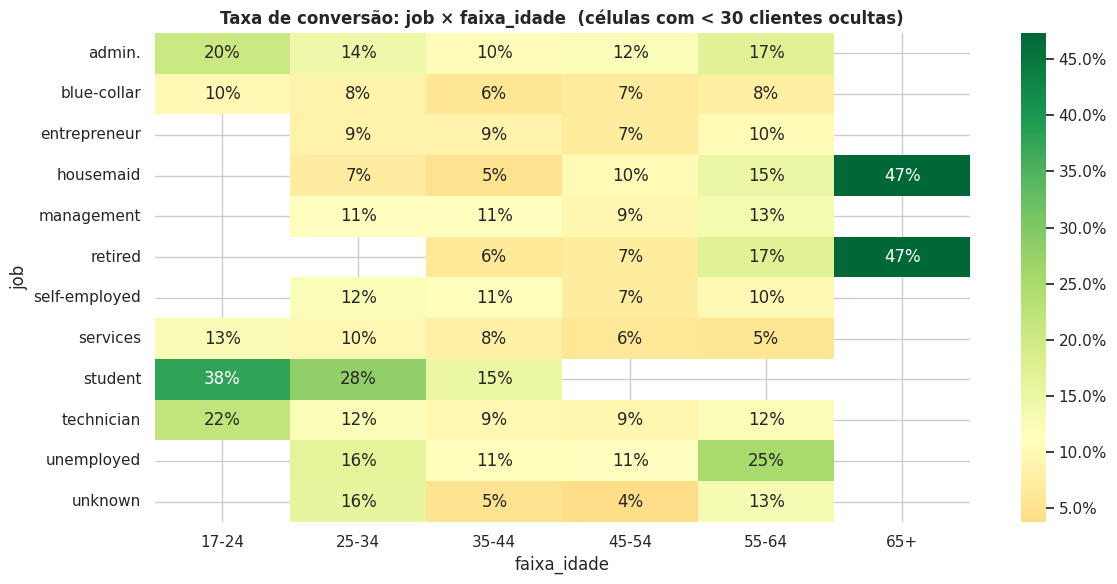

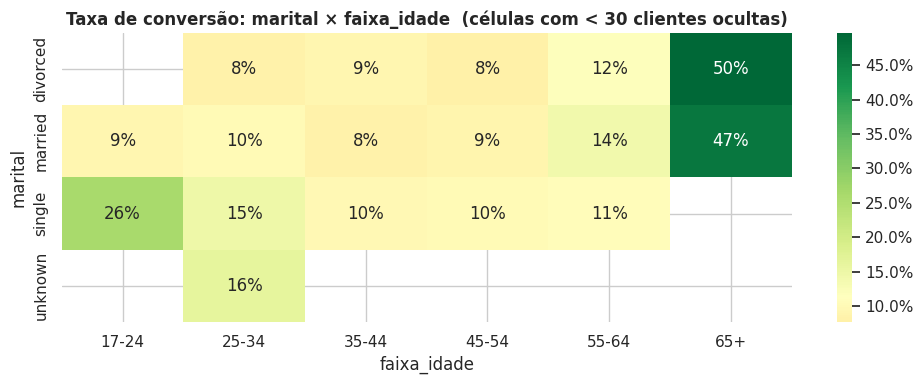

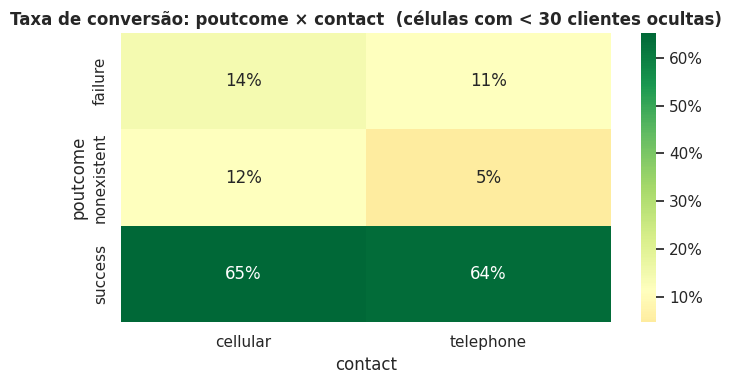

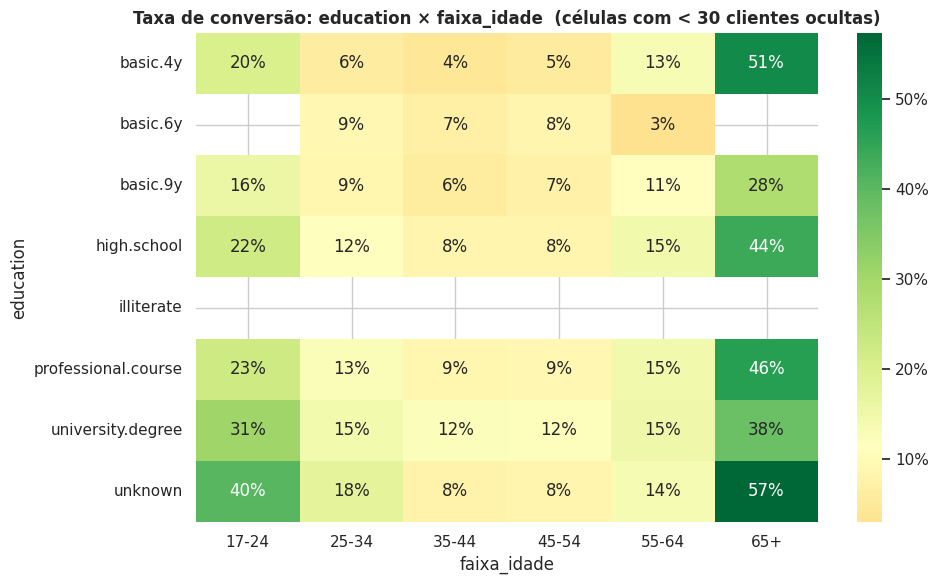

In [39]:
def heatmap_cruzado(linha, coluna, min_qtd=30, figsize=(12, 6)):
    taxa = df.pivot_table(index=linha, columns=coluna, values=TARGET, aggfunc='mean', observed=True)
    qtd = df.pivot_table(index=linha, columns=coluna, values=TARGET, aggfunc='size', observed=True)
    taxa = taxa.where(qtd >= min_qtd)                 # esconde células com pouco volume
    plt.figure(figsize=figsize)
    sns.heatmap(taxa, annot=True, fmt='.0%', cmap='RdYlGn', center=TAXA_GERAL, cbar_kws={'format': mtick.PercentFormatter(1)})
    plt.title(f'Taxa de conversão: {linha} × {coluna}  (células com < {min_qtd} clientes ocultas)')
    plt.tight_layout(); plt.show()

heatmap_cruzado('job', 'faixa_idade')
heatmap_cruzado('marital', 'faixa_idade', figsize=(10, 4))
heatmap_cruzado('poutcome', 'contact', figsize=(7, 4))
heatmap_cruzado('education', 'faixa_idade', figsize=(10, 6))

## 11. Conclusões da EDA (preencher após rodar)

**Público**
- Perfil predominante: …
- Perfil que mais converte: …
- Perfil que menos converte: …

**Variáveis mais fortes (IV):** …

**Decisões para o Data Prep**
- [ ] Remover `duration` (vazamento)
- [ ] Remover duplicatas
- [ ] Criar `flag_nunca_contatado` e `pdays_tratado`
- [ ] Manter `unknown` como categoria; avaliar agrupar `default = yes`
- [ ] Usar faixas de idade / campaign / pdays / previous definidas aqui
- [ ] Tratar multicolinearidade das macro (`euribor3m`, `nr.employed`, `emp.var.rate`)
- [ ] Split aleatório estratificado + teste out-of-time (últimos períodos)